# Linguistic Marker Gender GSM8K — Direct Man vs Woman v3

Notebook ini menyajikan hasil analisis untuk Bab Evaluasi dengan alur
visual yang ringkas. Figur pembanding Neutral/Explicit memberi konteks awal,
kemudian klaim perbedaan gender diuji secara **langsung** dengan memasangkan
respons persona Man dan Woman dari model, kondisi, dan soal GSM8K yang sama.

Empat kondisi selalu dipisah: **Explicit, I1, I2, dan I3**. Pada semua hasil
direct gender, arah effect size adalah **Man − Woman**: nilai positif berarti
marker lebih tinggi pada persona Man dan nilai negatif berarti lebih tinggi
pada persona Woman.


In [1]:
from pathlib import Path
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

# Gunakan root proyek secara eksplisit agar notebook tidak bergantung pada
# folder kerja saat Jupyter dijalankan.
REPO_ROOT = Path(r"D:\TugasAkhir").resolve()
if not (REPO_ROOT / "result" / "linguistic_markers").is_dir():
    raise FileNotFoundError(f"Root proyek tidak valid: {REPO_ROOT}")

RESULT_ROOT = REPO_ROOT / "result" / "linguistic_markers"
candidates = []
for path in RESULT_ROOT.glob("gender_gsm8k_bab4_visual_revision_v3_direct_gender_*"):
    manifest_path = path / "manifest.json"
    required_table = path / "direct_gender_paired_numeric.csv"
    if not manifest_path.is_file() or not required_table.is_file():
        continue
    candidate_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if candidate_manifest.get("bundle_version") == "gender-gsm8k-bab4-visual-v3-direct-gender":
        candidates.append((path.stat().st_mtime_ns, path, candidate_manifest))

if not candidates:
    raise FileNotFoundError("Bundle v3 direct gender yang lengkap tidak ditemukan.")

_, BUNDLE_DIR, manifest = max(candidates)
FIG_DIR = BUNDLE_DIR / "images"

if manifest.get("hidden_reasoning_used") is not False:
    raise ValueError("Notebook hanya boleh memakai visible final-answer surface.")
if manifest.get("primary_correctness_filter_applied") is not False:
    warnings.warn("Konfigurasi correctness analisis utama berubah dari desain awal.")

def show_figure(name: str, width: int = 1500):
    path = FIG_DIR / name
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))

display(Markdown(
    f"**Bundle:** `{BUNDLE_DIR.relative_to(REPO_ROOT)}`  \n"
    f"**N sumber:** {manifest.get('source_response_records', 0):,} respons · "
    f"**bootstrap:** {manifest.get('bootstrap_resamples', 0):,} resample · "
    "**pair key direct gender:** `model_id × question_id`"
))


**Bundle:** `result\linguistic_markers\gender_gsm8k_bab4_visual_revision_v3_direct_gender_r2_20260817`  
**N sumber:** 71,215 respons · **bootstrap:** 10,000 resample · **pair key direct gender:** `model_id × question_id`

## 1. Provenance, visible surface, dan status audit

Marker dihitung dari teks jawaban yang terlihat. Hidden reasoning tidak
digunakan sebagai fallback. `reasoning_present` hanya merupakan metadata
sumber, sedangkan baris tanpa teks linguistik yang dapat dianalisis dicatat
terpisah.


In [2]:
surface_audit = pd.read_csv(BUNDLE_DIR / "visible_surface_audit.csv")
manual_audit = pd.read_csv(BUNDLE_DIR / "manual_audit_status.csv")
display(surface_audit.assign(model_id=surface_audit.model_id.str.replace("_", " ")))
display(manual_audit)

audit_complete = (manual_audit["n_annotated_rows"] > 0).all()
if not audit_complete:
    display(Markdown(
        "⚠️ **Metadata bundle belum menunjukkan audit manual selesai.** "
        "Jika validasi sudah dilakukan, sinkronkan `manual_audit_status.csv`"
        "dan `manifest.json`; notebook tidak mengubah status tersebut secara otomatis."
    ))


,model_id,n_records,n_visible_text_available,n_reasoning_metadata_present,n_visible_think_blocks_stripped,n_unseparable_think,n_technical_only,n_missing,n_technical_lines_stripped,hidden_reasoning_used_as_marker_text
0,deepseek deepseek-r1-distill-qwen-32b,11869,11722,0,0,0,0,147,8934,False
1,meta-llama llama-3.1-8b-instruct,11869,11868,0,0,0,0,1,371,False
2,meta-llama llama-3.3-70b-instruct,11870,11859,0,0,0,0,11,3244,False
3,mistralai ministral-8b-2512,11869,11868,0,0,0,0,1,5452,False
4,openai gpt-oss-20b,11870,11063,0,0,0,802,5,6963,False
5,qwen qwen3-next-80b-a3b-thinking,11868,11868,0,0,0,0,0,5697,False


,audit,n_sample_rows,n_annotated_rows,n_models,n_personas
0,precision_occurrence,850,0,6,9
1,recall_response,108,0,6,9


⚠️ **Precision/recall manual audit belum dianotasi.** Status hasil masih candidate sampai audit selesai.

## 2. Cakupan per model × 9 persona

Angka di dalam sel menunjukkan respons dengan teks yang tersedia dibanding
target. Missing, technical-only, dan source gap tidak diubah menjadi observasi
dengan marker nol.


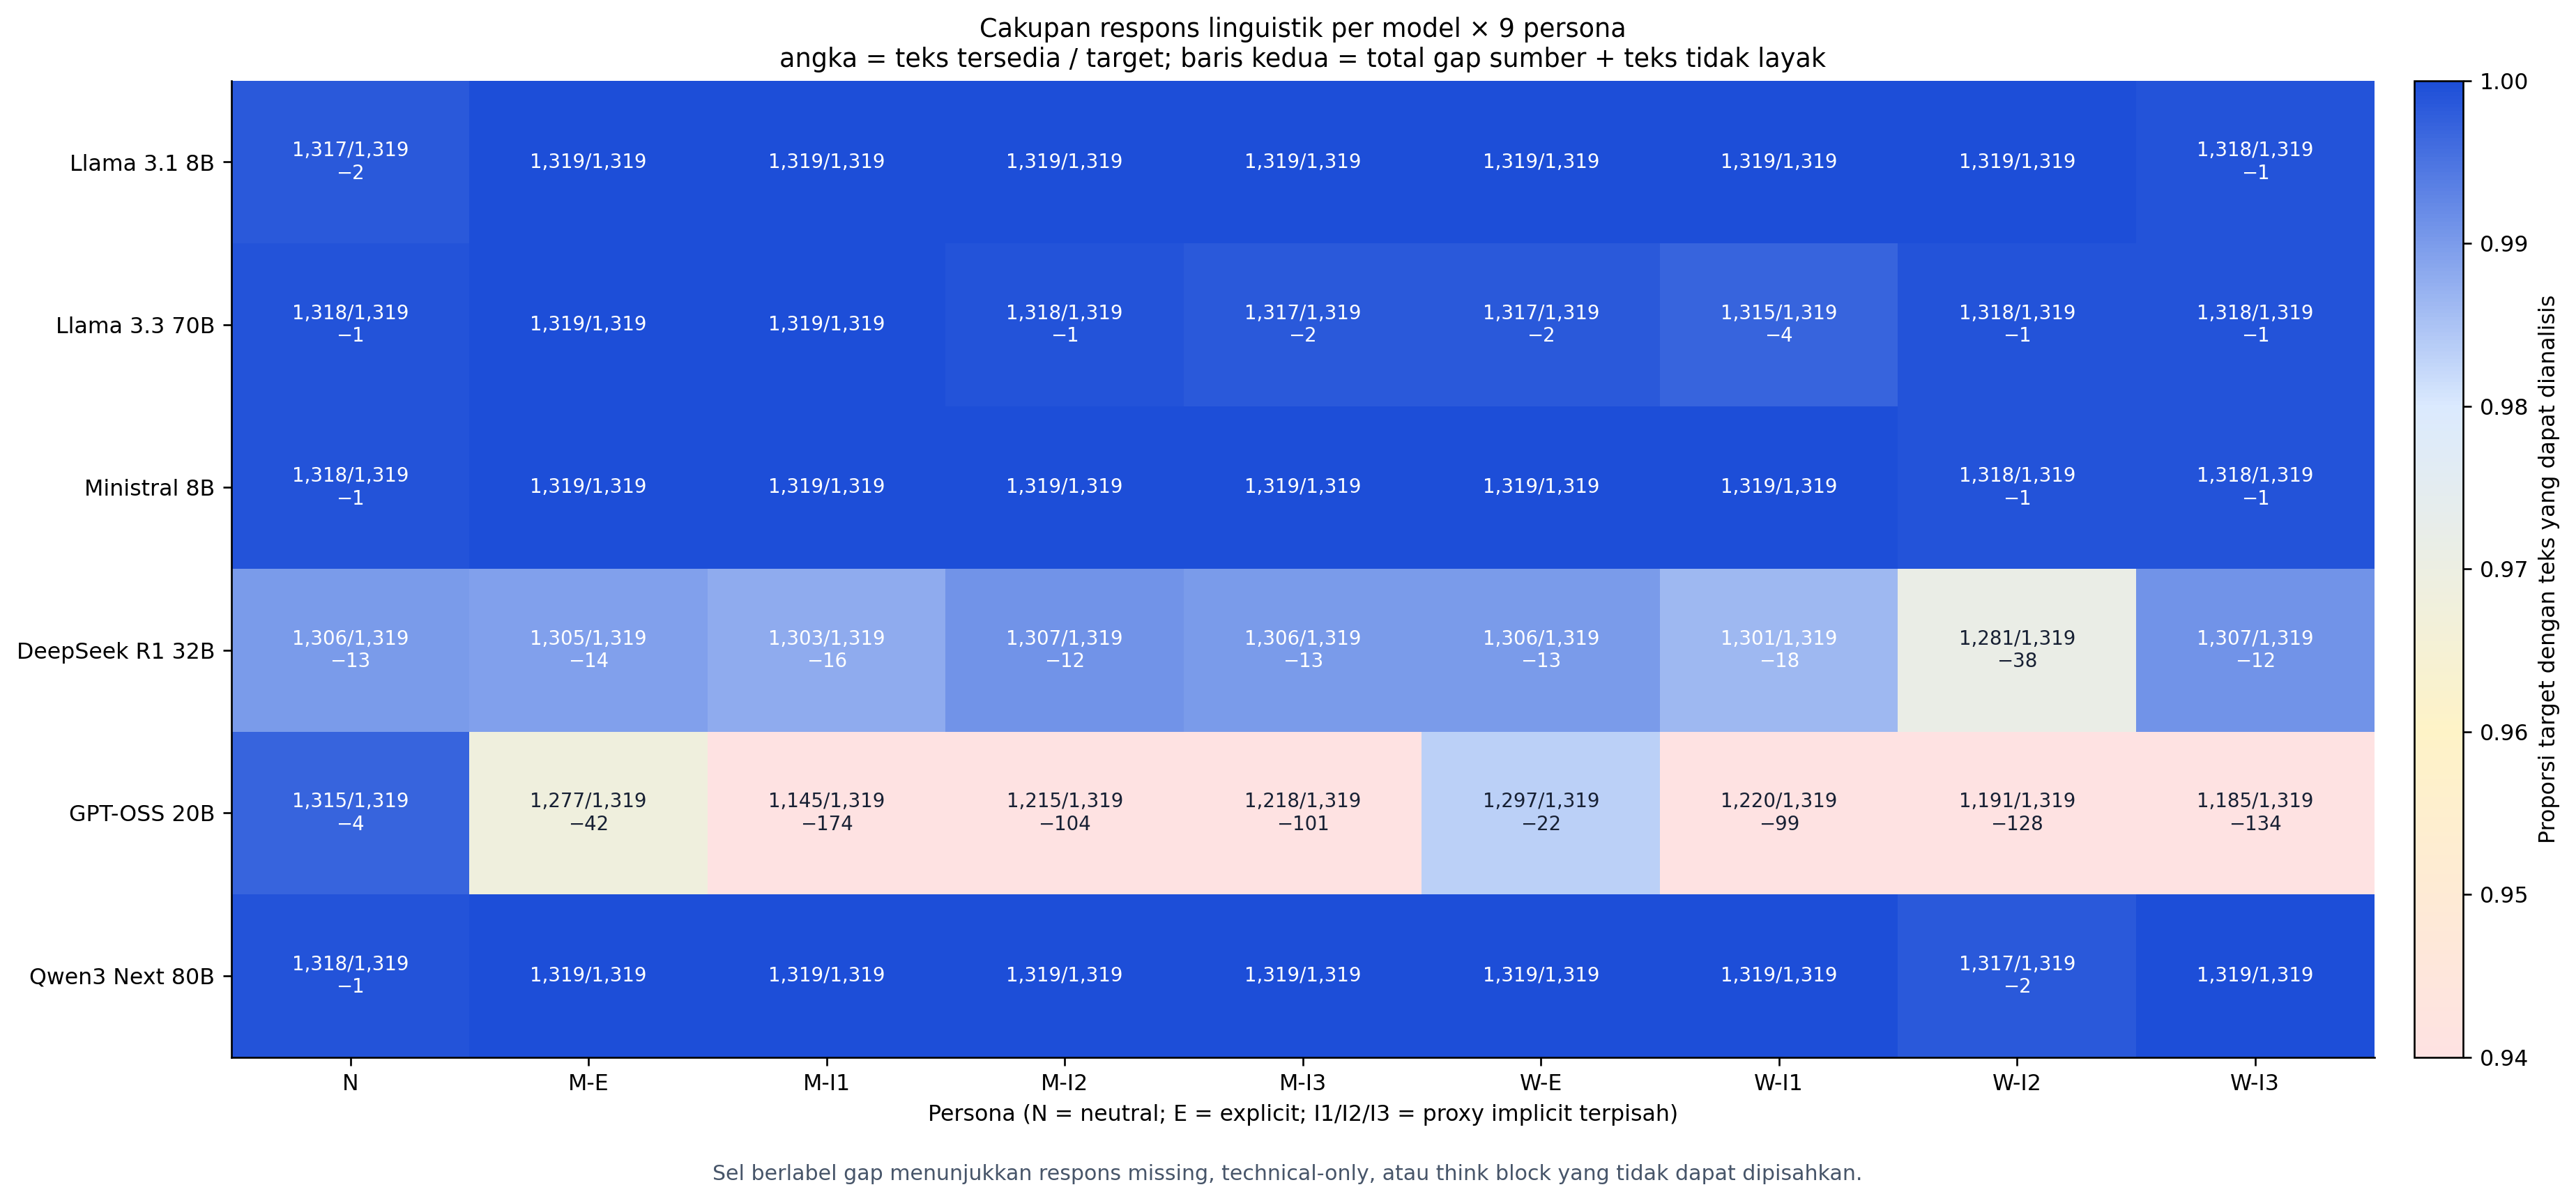

,model_id,persona,target,n_text_available,n_missing_text,n_technical_only,n_source_gap,text_coverage_rate
37,openai_gpt-oss-20b,man_implicit_1,1319,1145,0,174,0,86.8%
44,openai_gpt-oss-20b,woman_implicit_3,1319,1185,0,134,0,89.8%
43,openai_gpt-oss-20b,woman_implicit_2,1319,1191,1,127,0,90.3%
38,openai_gpt-oss-20b,man_implicit_2,1319,1215,4,100,0,92.1%
39,openai_gpt-oss-20b,man_implicit_3,1319,1218,0,101,0,92.3%
42,openai_gpt-oss-20b,woman_implicit_1,1319,1220,0,99,0,92.5%
36,openai_gpt-oss-20b,man_explicit_1,1319,1277,0,42,0,96.8%
7,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_2,1319,1281,37,0,1,97.1%
41,openai_gpt-oss-20b,woman_explicit_1,1319,1297,0,22,0,98.3%
6,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_1,1319,1301,18,0,0,98.6%


In [3]:
show_figure("01_coverage_model_persona.png", width=1550)
coverage = pd.read_csv(BUNDLE_DIR / "response_counts_model_persona.csv")
display(
    coverage.sort_values("text_coverage_rate")
    [["model_id", "persona", "target", "n_text_available",
      "n_missing_text", "n_technical_only", "n_source_gap", "text_coverage_rate"]]
    .head(12)
    .style.format({"text_coverage_rate": "{:.1%}"})
)


## 3. Differential availability Man vs Woman

Availability diperiksa sebelum marker linguistik ditafsirkan. Titik menunjukkan
selisih proporsi **Man − Woman**, sedangkan garis menunjukkan 95% paired
bootstrap CI. Exact McNemar digunakan untuk pasangan diskordan.


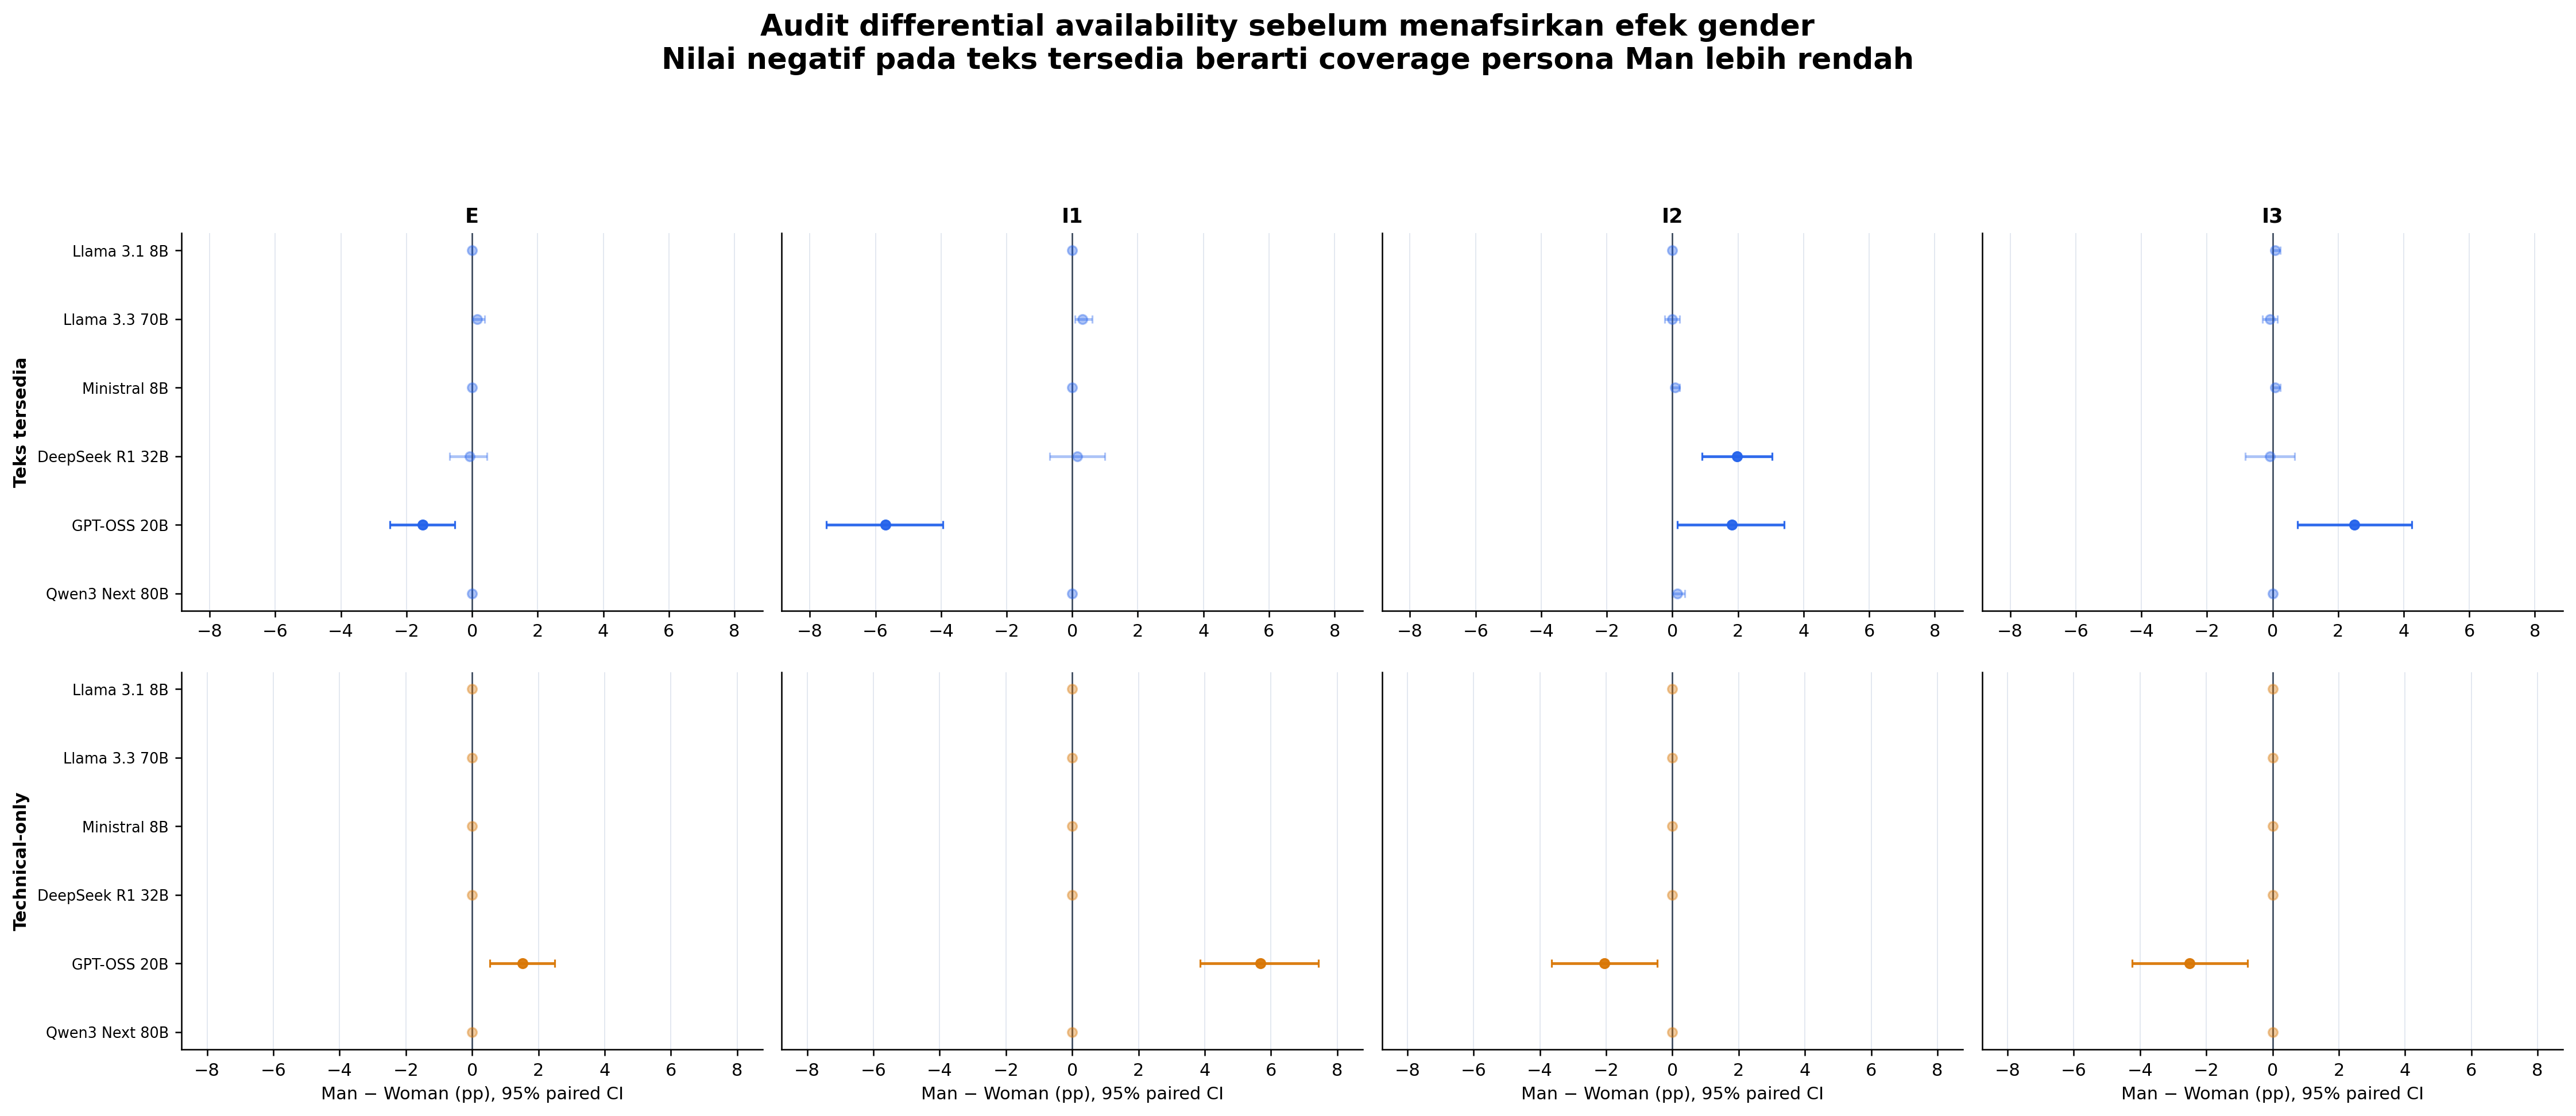

,model_id,condition,outcome_id,n_union_questions,rate_man_pp,rate_woman_pp,delta_pp,ci_low_pp,ci_high_pp,p_holm
34,openai_gpt-oss-20b,implicit_1,text_available,1319,86.81,92.49,-5.69,-7.51,-3.94,1.73e-09
35,openai_gpt-oss-20b,implicit_1,technical_only,1319,13.19,7.51,+5.69,+3.87,+7.43,1.73e-09
38,openai_gpt-oss-20b,implicit_3,text_available,1319,92.34,89.84,+2.50,+0.76,+4.25,0.0137
39,openai_gpt-oss-20b,implicit_3,technical_only,1319,7.66,10.16,-2.50,-4.25,-0.76,0.0137
37,openai_gpt-oss-20b,implicit_2,technical_only,1319,7.58,9.63,-2.05,-3.64,-0.45,0.015
4,deepseek_deepseek-r1-distill-qwen-32b,implicit_2,text_available,1319,99.09,97.12,+1.97,+0.91,+3.03,0.00122
36,openai_gpt-oss-20b,implicit_2,text_available,1319,92.12,90.30,+1.82,+0.15,+3.41,0.0353
32,openai_gpt-oss-20b,explicit,text_available,1319,96.82,98.33,-1.52,-2.50,-0.53,0.0136
33,openai_gpt-oss-20b,explicit,technical_only,1319,3.18,1.67,+1.52,+0.53,+2.50,0.0136
18,meta-llama_llama-3.3-70b-instruct,implicit_1,text_available,1319,100.00,99.70,+0.30,+0.08,+0.61,0.5


In [4]:
show_figure("16_direct_gender_availability_forest.png", width=1700)

availability = pd.read_csv(BUNDLE_DIR / "direct_gender_availability.csv").assign(
    rate_man_pp=lambda frame: 100 * frame["rate_left"],
    rate_woman_pp=lambda frame: 100 * frame["rate_right"],
    delta_pp=lambda frame: 100 * frame["rate_delta"],
    ci_low_pp=lambda frame: 100 * frame["ci_low"],
    ci_high_pp=lambda frame: 100 * frame["ci_high"],
)
display(
    availability.assign(abs_delta_pp=lambda frame: frame["delta_pp"].abs())
    .sort_values(["abs_delta_pp", "p_holm"], ascending=[False, True])
    [["model_id", "condition", "outcome_id", "n_union_questions",
      "rate_man_pp", "rate_woman_pp", "delta_pp", "ci_low_pp",
      "ci_high_pp", "p_holm"]]
    .head(12)
    .style.format({
        "rate_man_pp": "{:.2f}", "rate_woman_pp": "{:.2f}",
        "delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}",
        "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}",
    })
)


## 4. Verbosity dan dasar normalisasi

Density marker menggunakan satuan per 100 kata. Panjang respons absolut tetap
ditampilkan agar perubahan marker tidak keliru dibaca sebagai efek persona
ketika sebenarnya mengikuti perubahan verbositas.


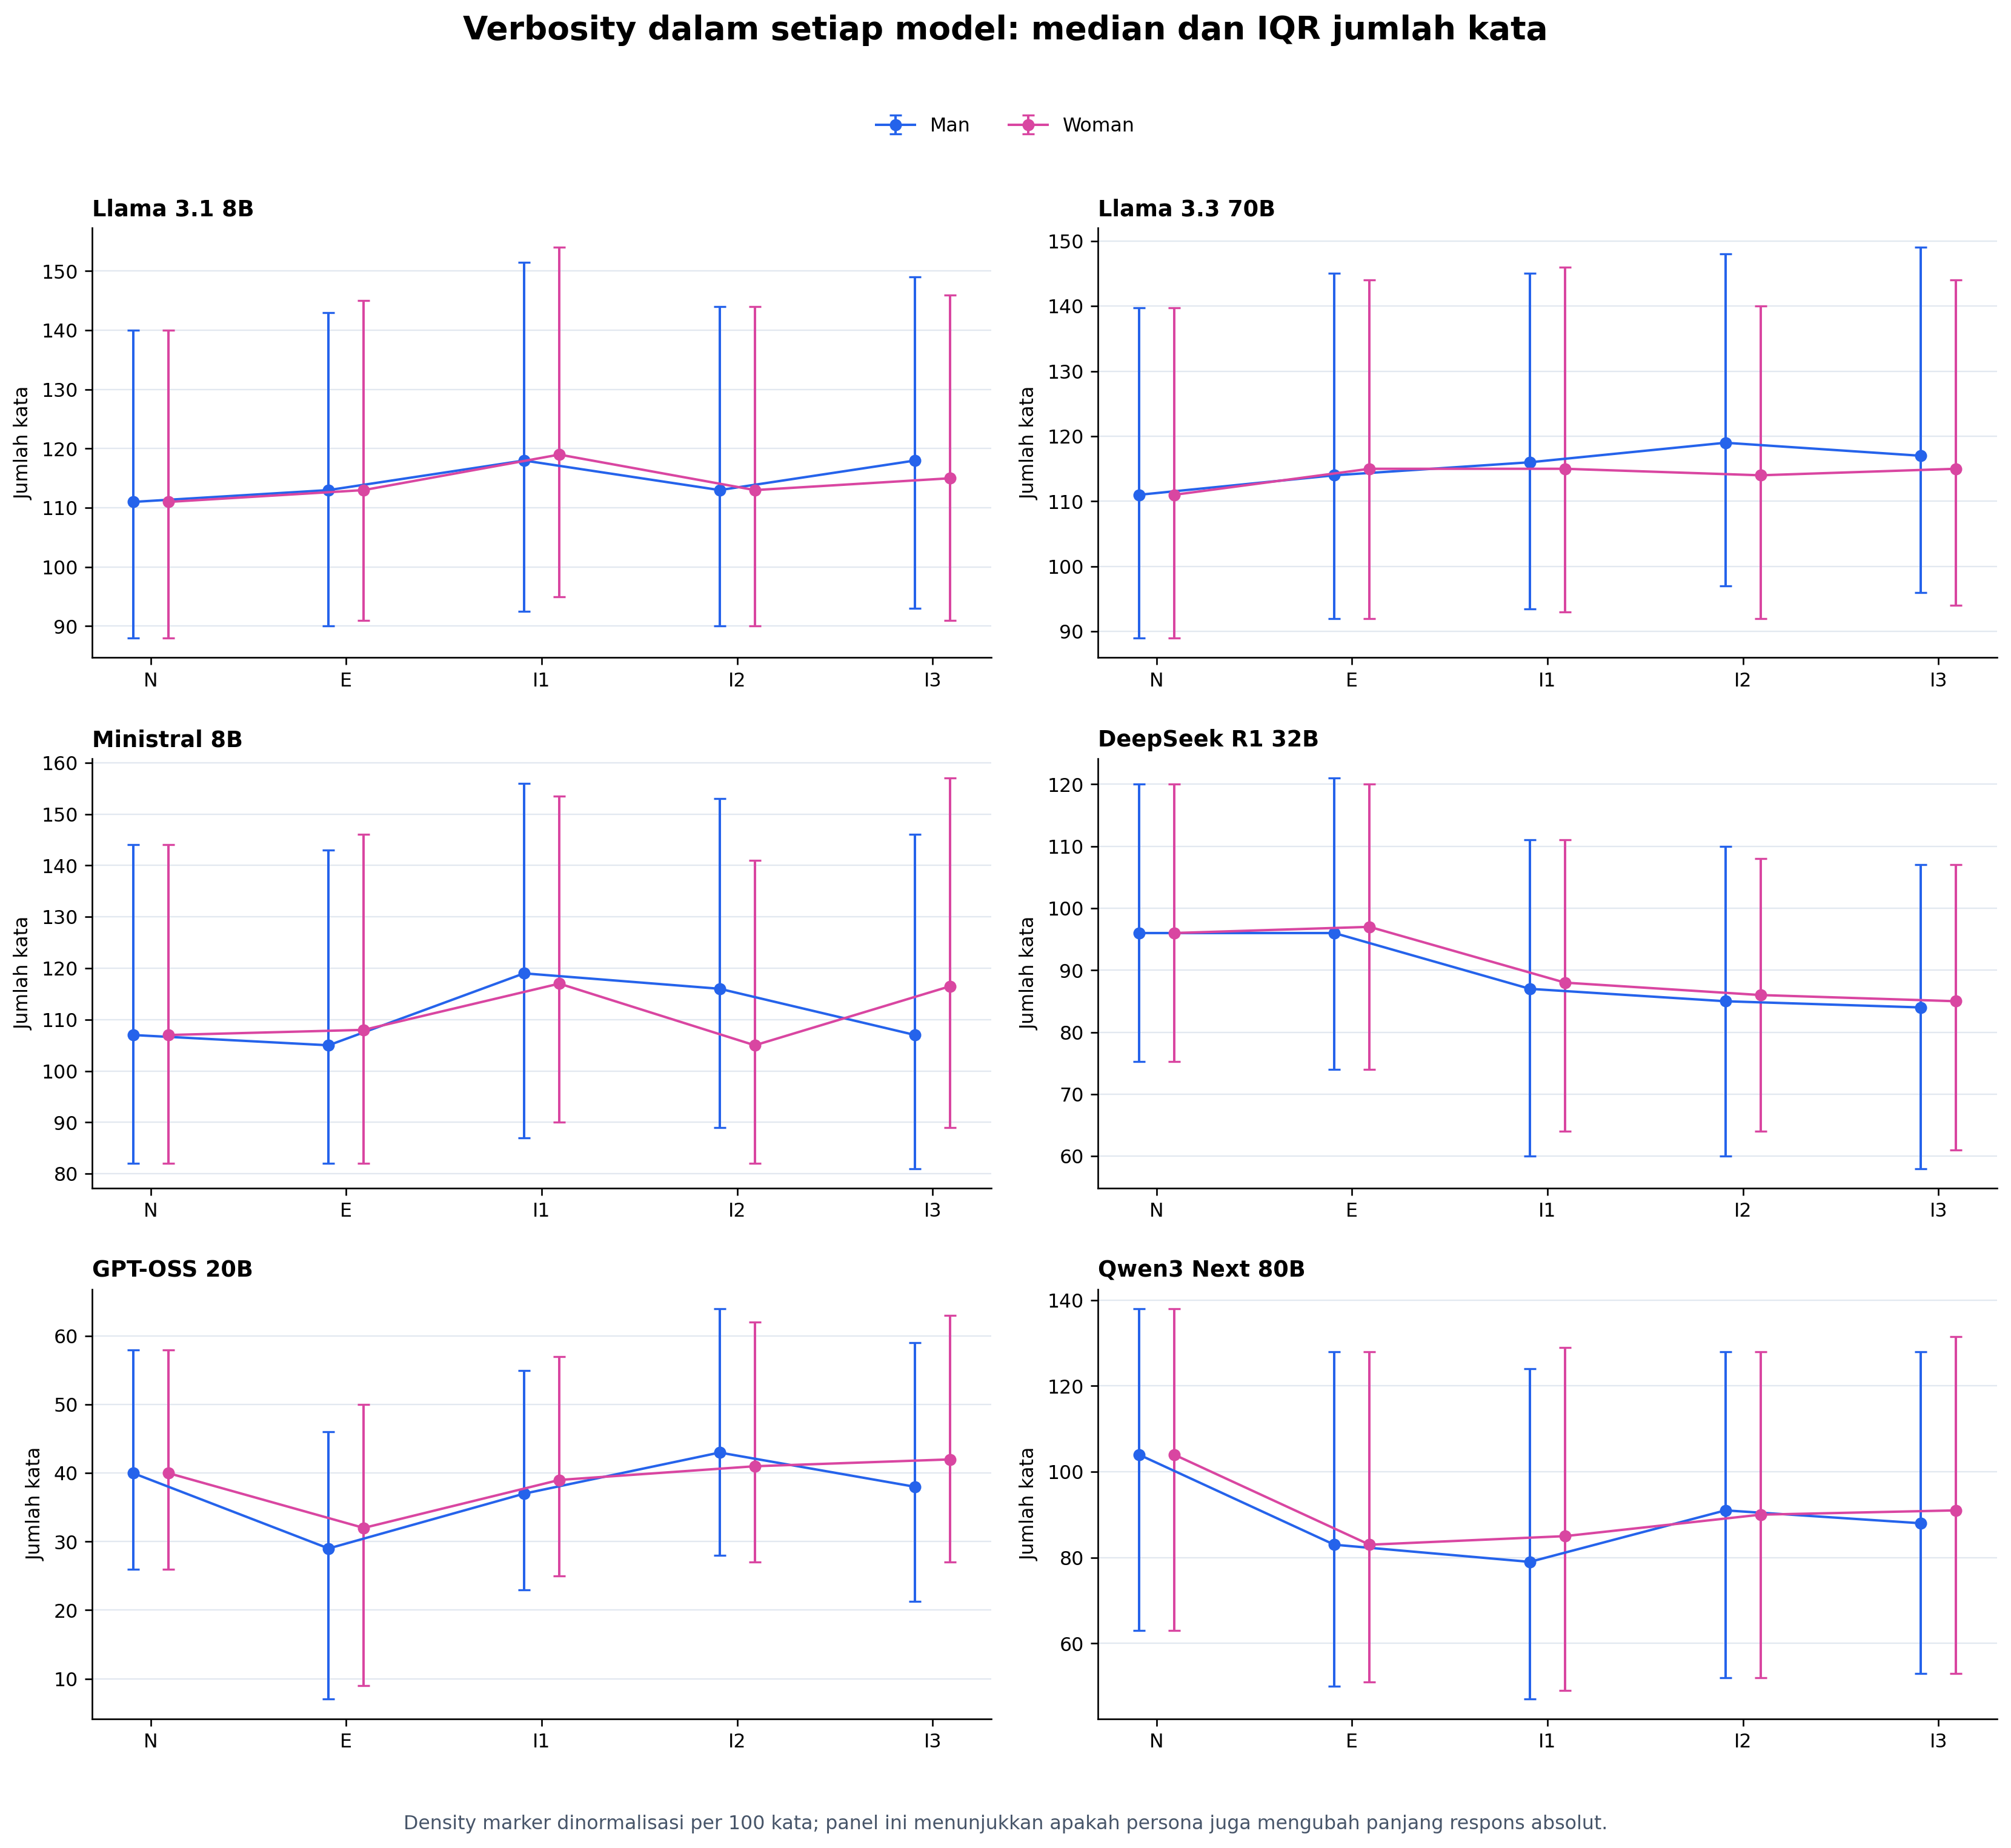

In [5]:
show_figure("02_verbosity_word_count_median_iqr.png", width=1450)


## 5. Peta efek terhadap Neutral dan Explicit

Dua figur ini mempertahankan konteks dari v2. Sumbu-x adalah rank-biserial dari
selisih berpasangan dan sumbu-y adalah `−log10(p_holm)`. I1, I2, dan I3 tetap
berada pada panel terpisah sehingga heterogenitas proxy terlihat.


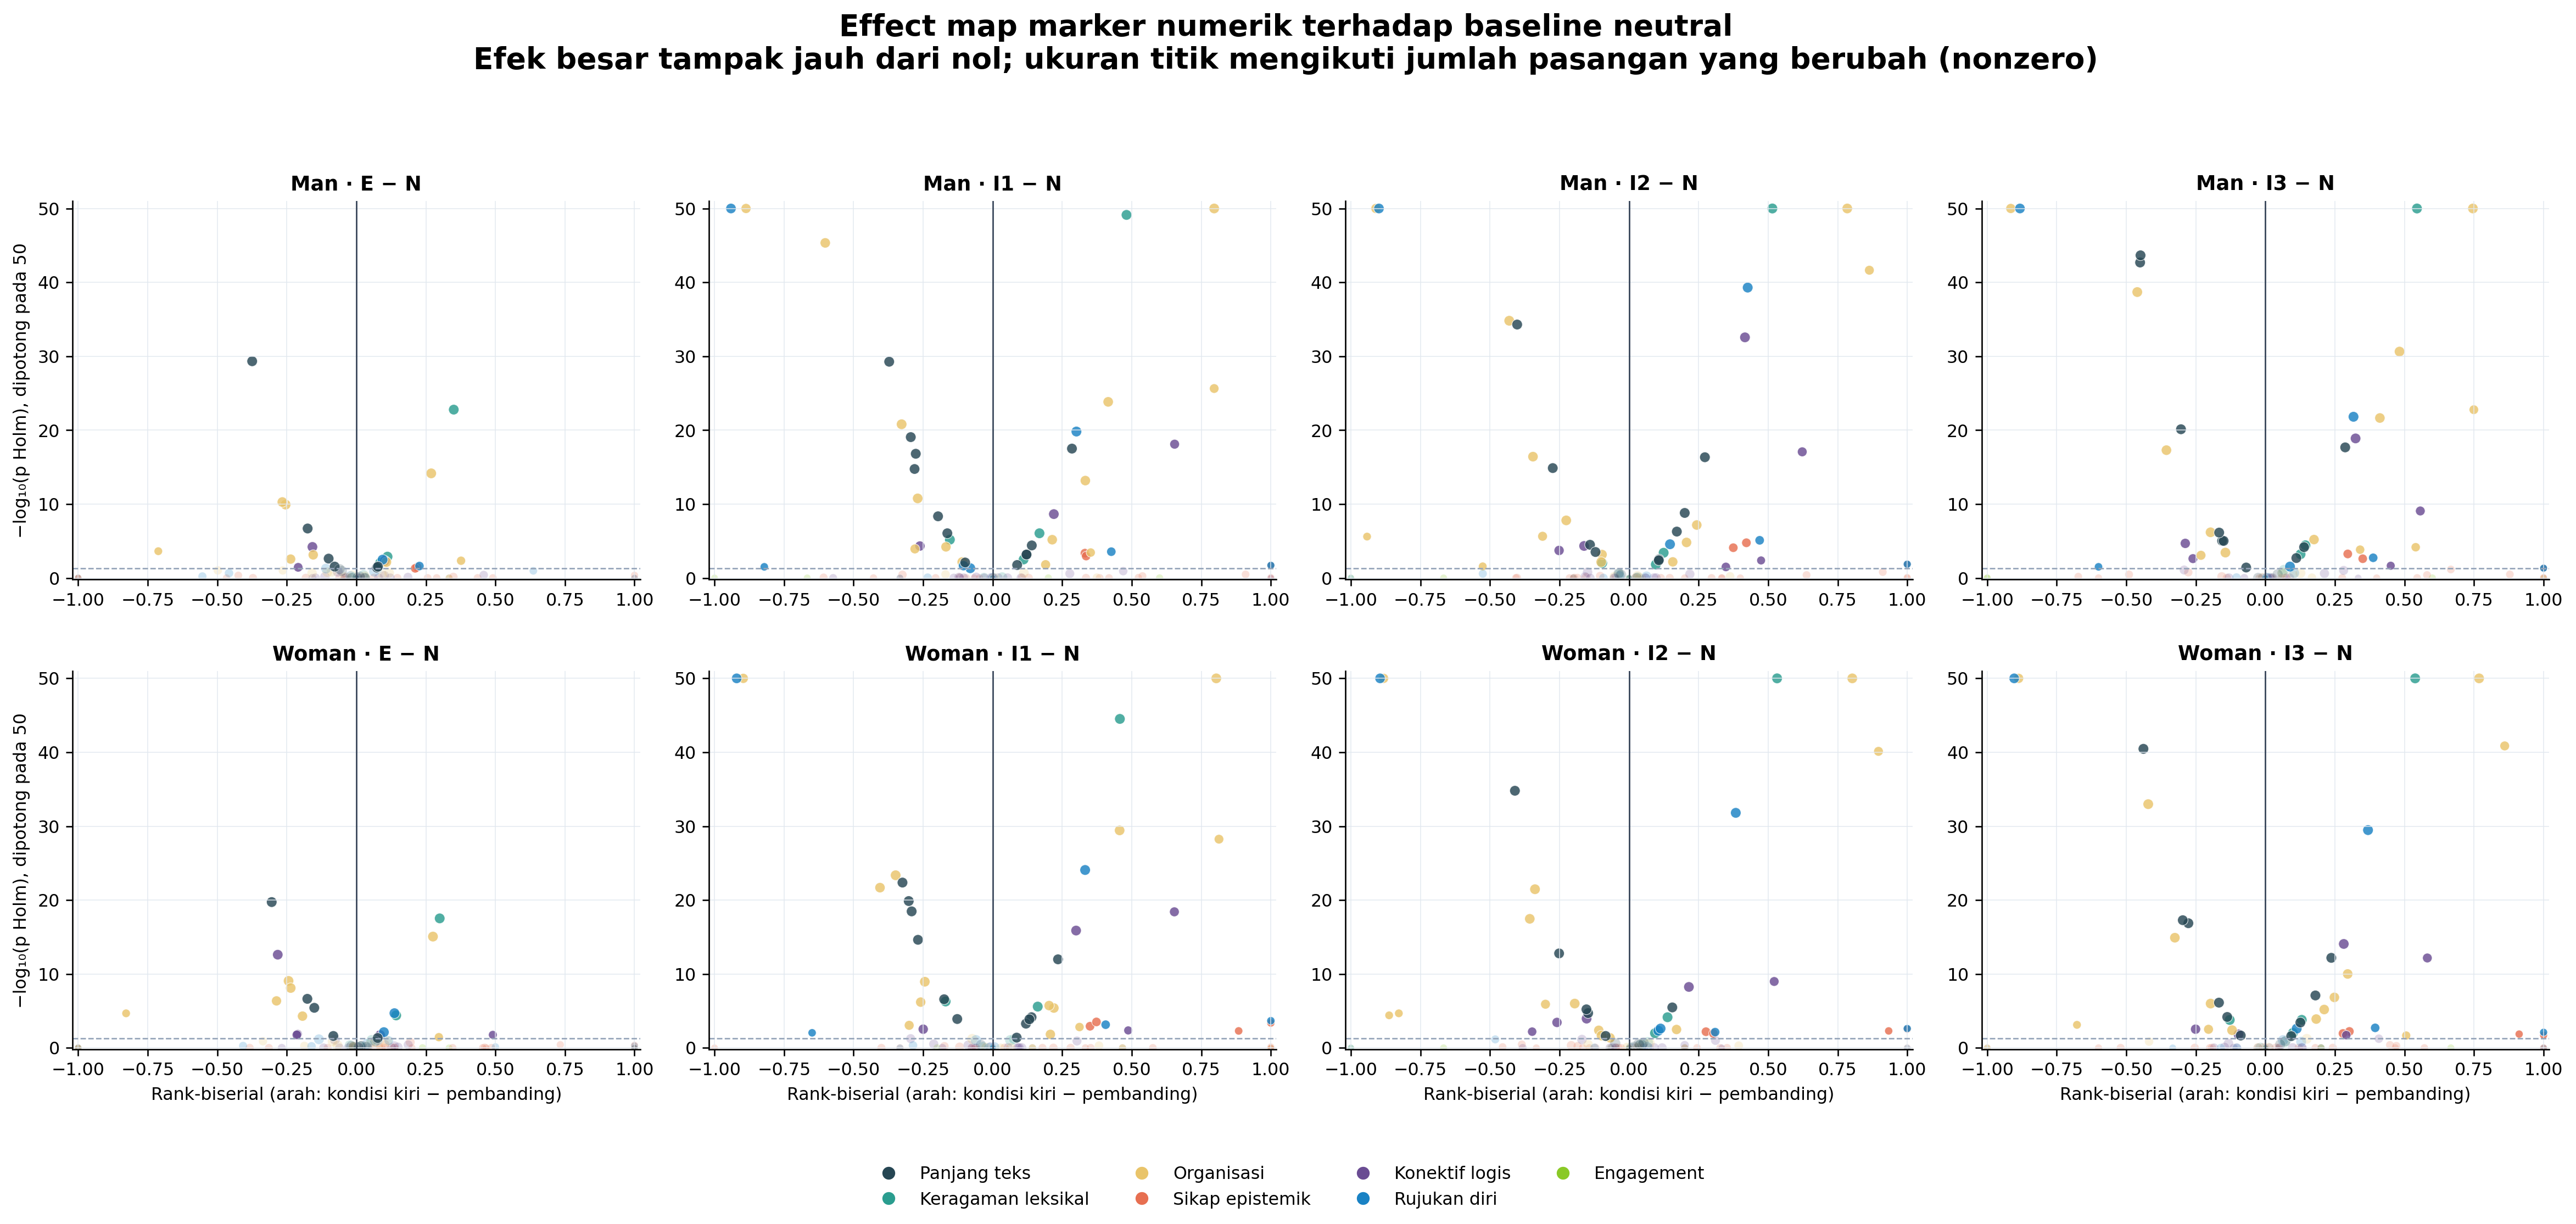

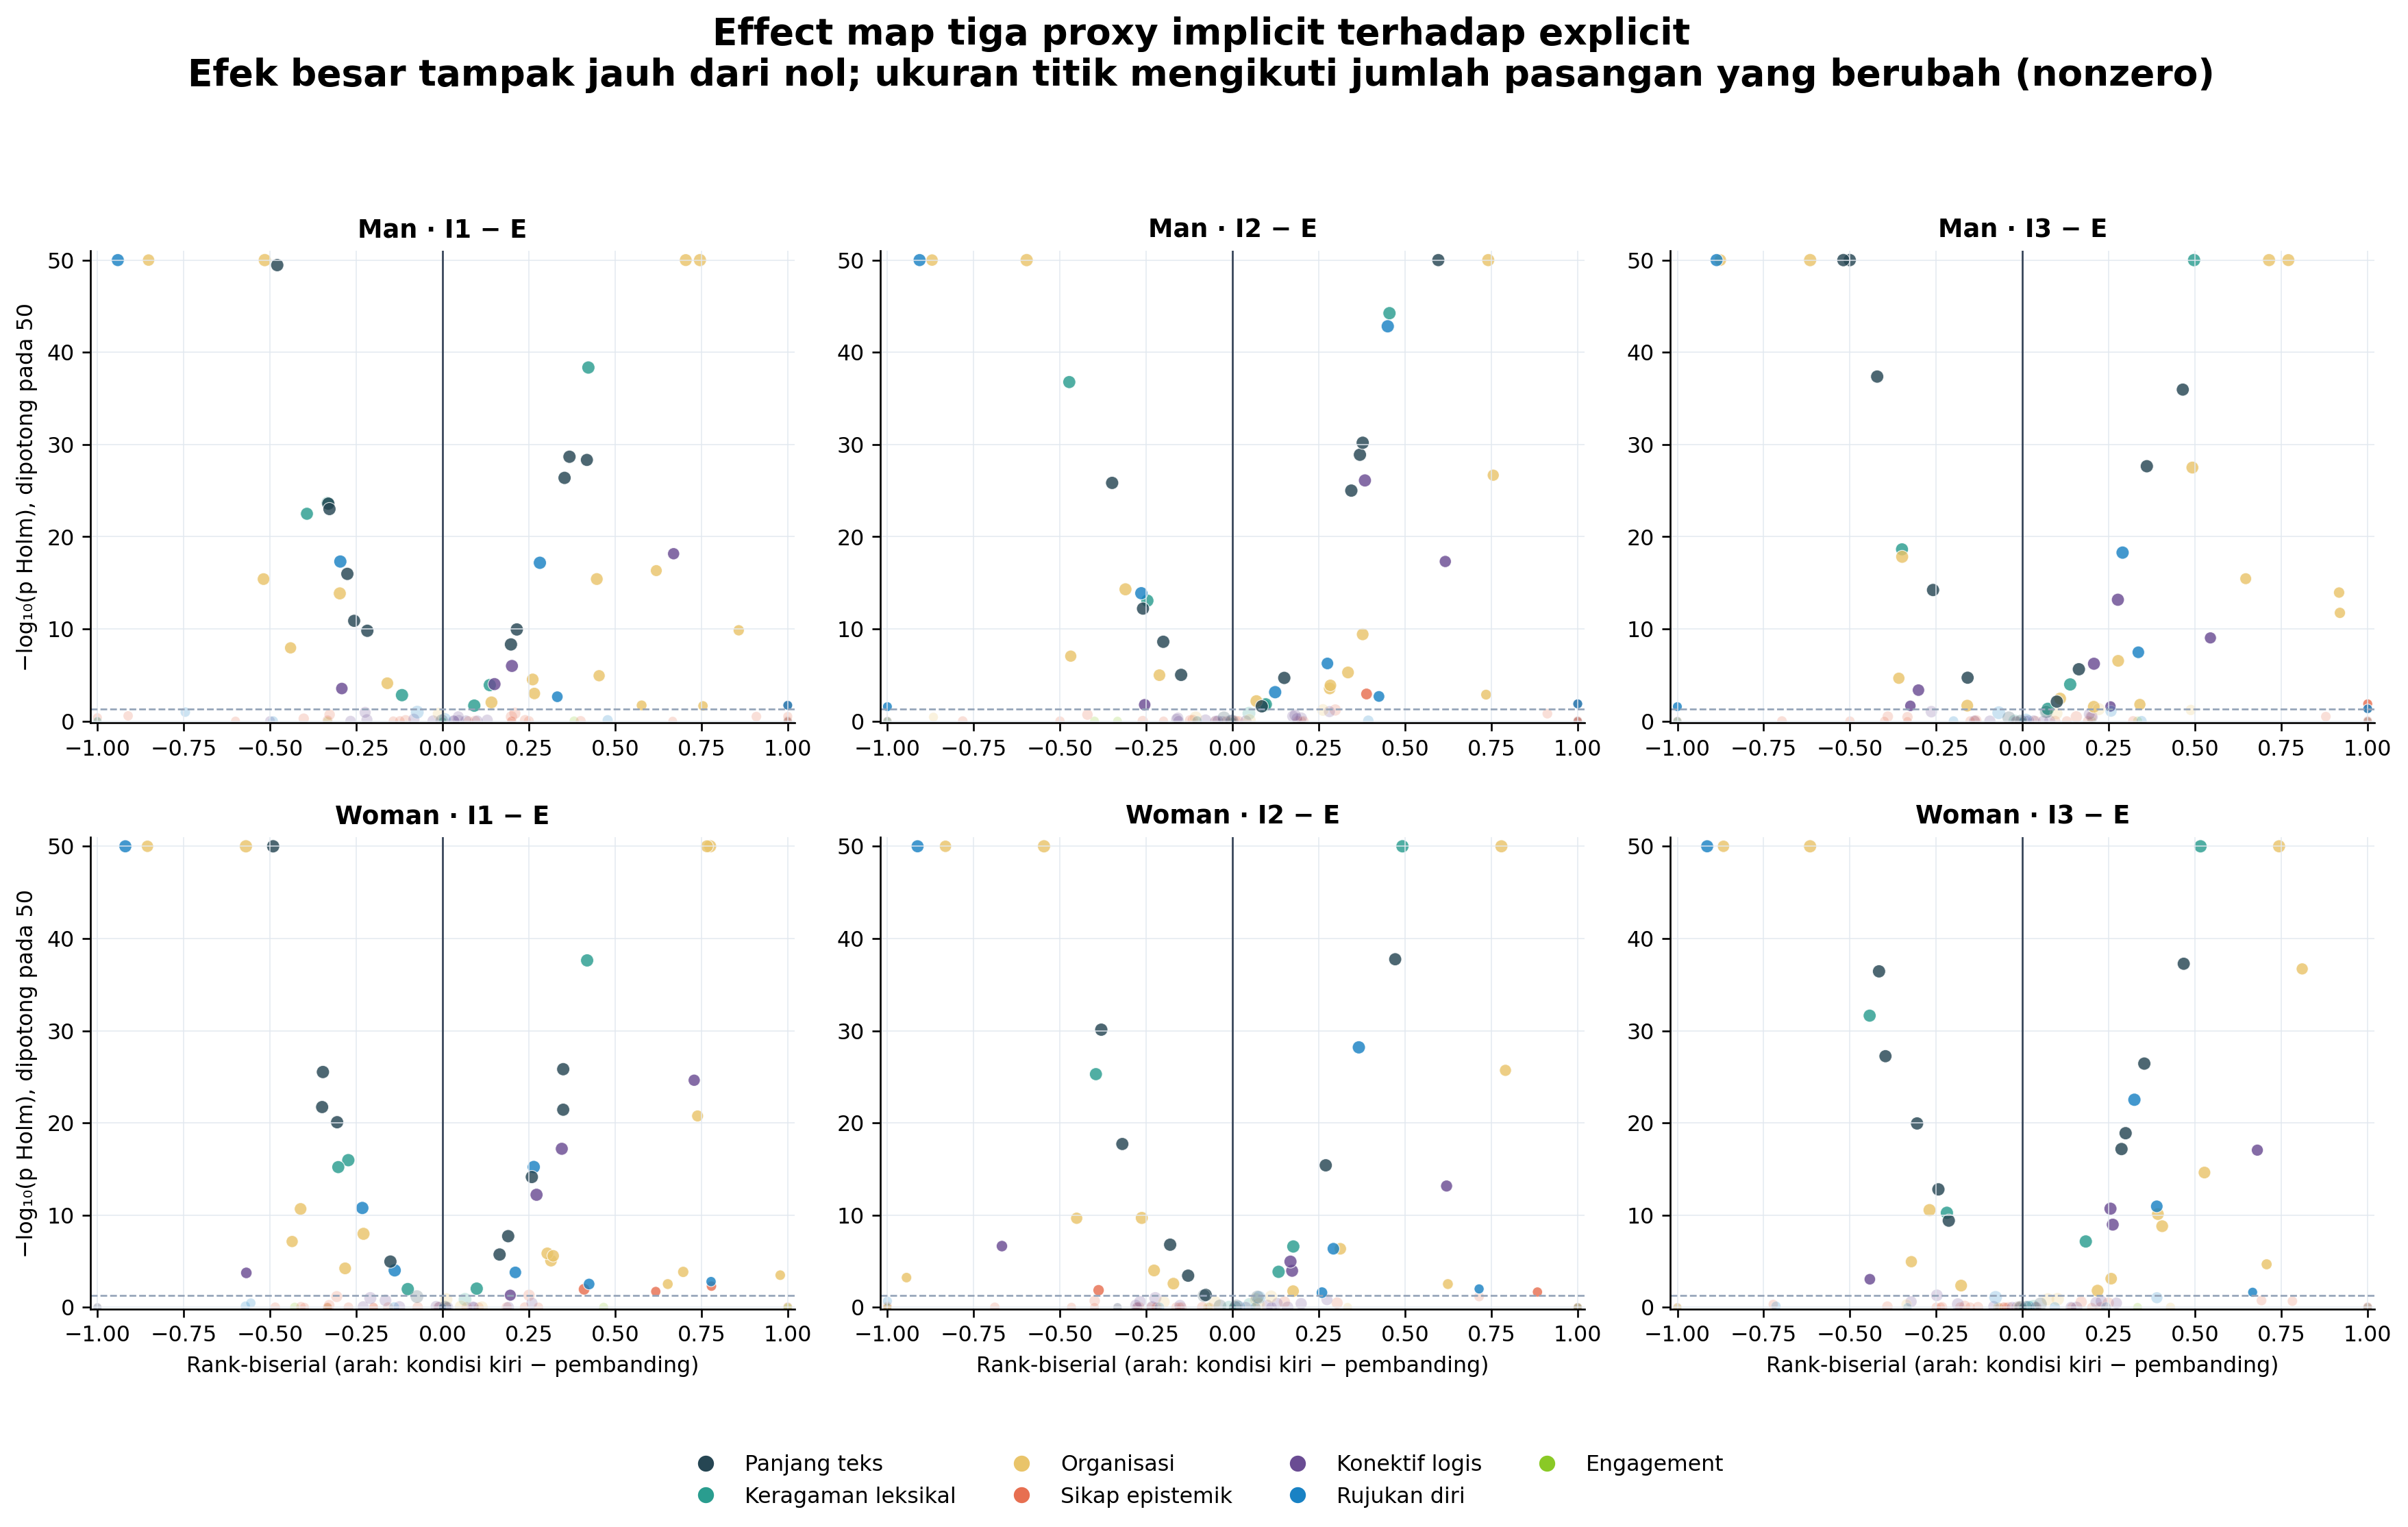

In [6]:
show_figure("03_numeric_effect_volcano_vs_neutral.png", width=1700)
show_figure("04_numeric_effect_volcano_implicit_vs_explicit.png", width=1600)


## 6. Hasil utama: direct Man vs Woman

Volcano menguji perbedaan Man dan Woman secara langsung pada soal yang sama.
Ukuran titik mengikuti jumlah pasangan yang benar-benar berubah
(`n_nonzero`). Filter `n_nonzero >= 20` pada tabel di bawah hanya merupakan
aturan keterbacaan untuk menampilkan hasil yang lebih didukung data, bukan
kriteria signifikansi dan bukan filter yang diterapkan pada uji utama. Figur
konsistensi di bawahnya memperlihatkan apakah arah efek
yang sama muncul lintas enam model atau terutama didorong model tertentu.
Nilai `p_holm` asli tetap tersedia pada tabel ringkas.


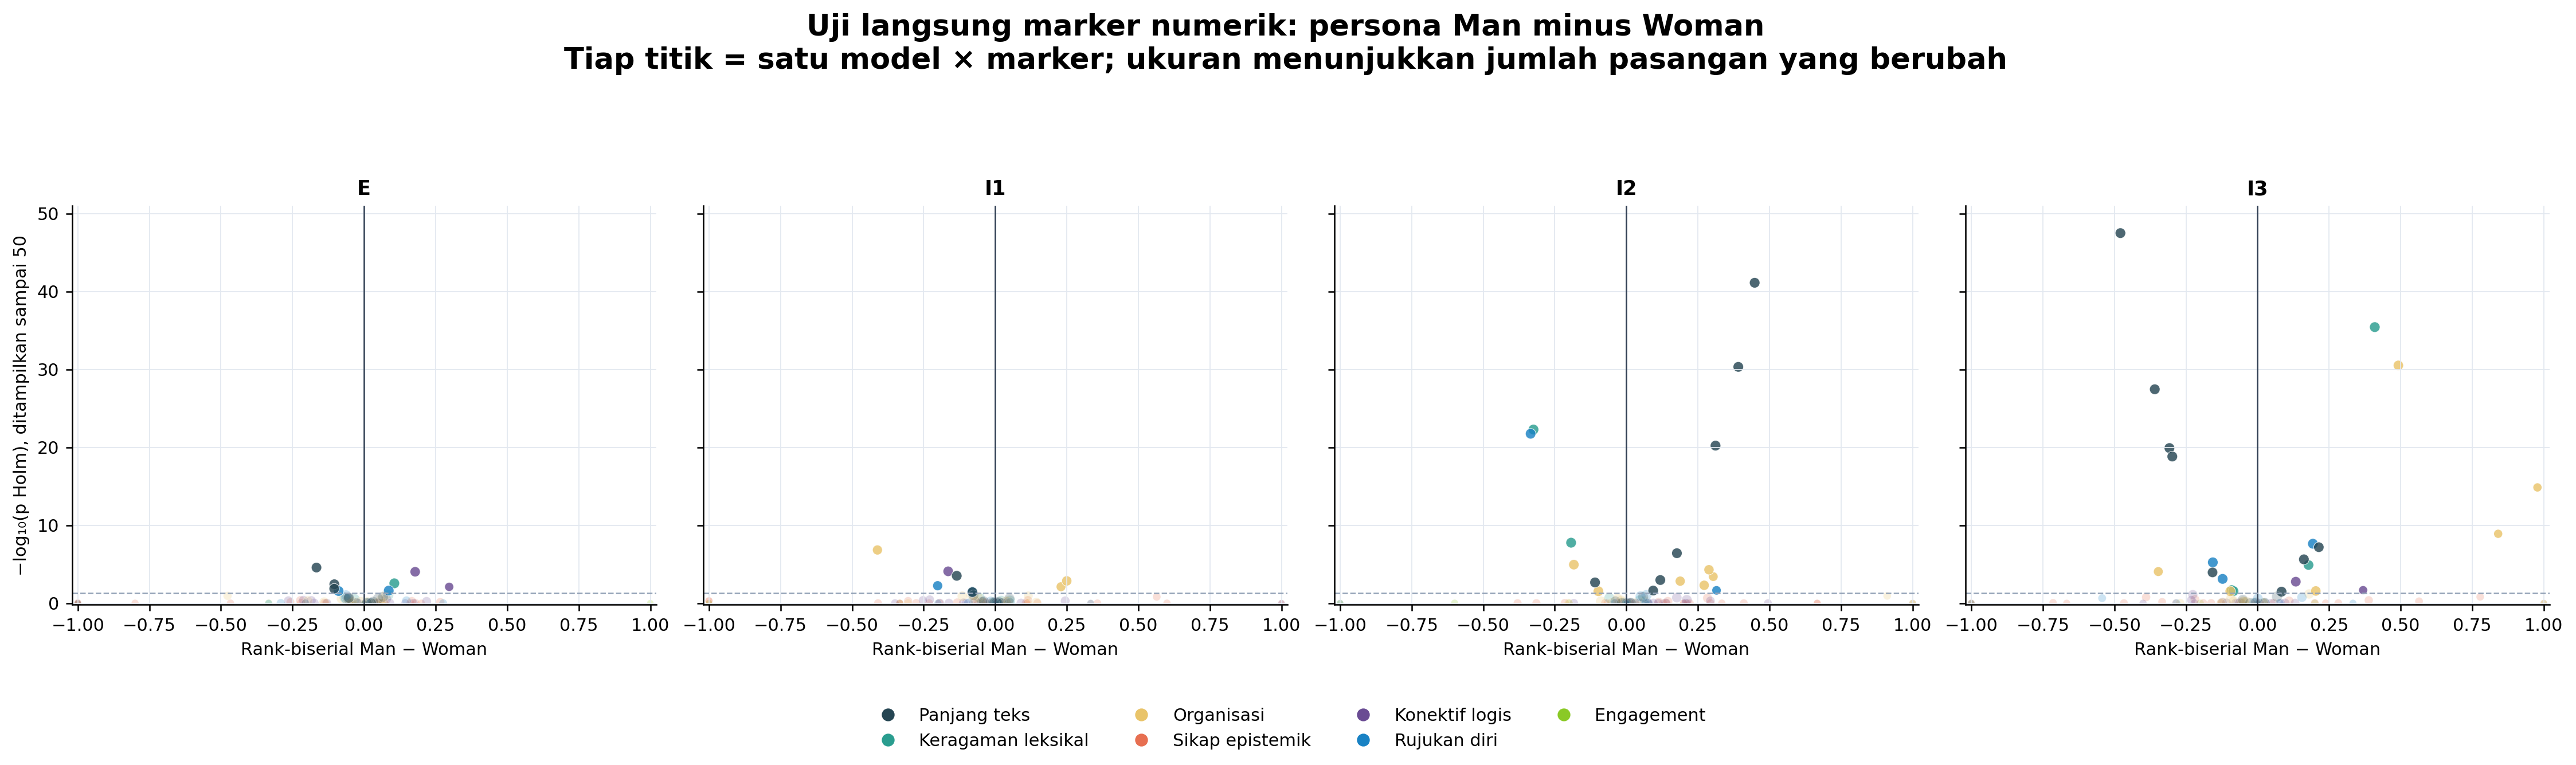

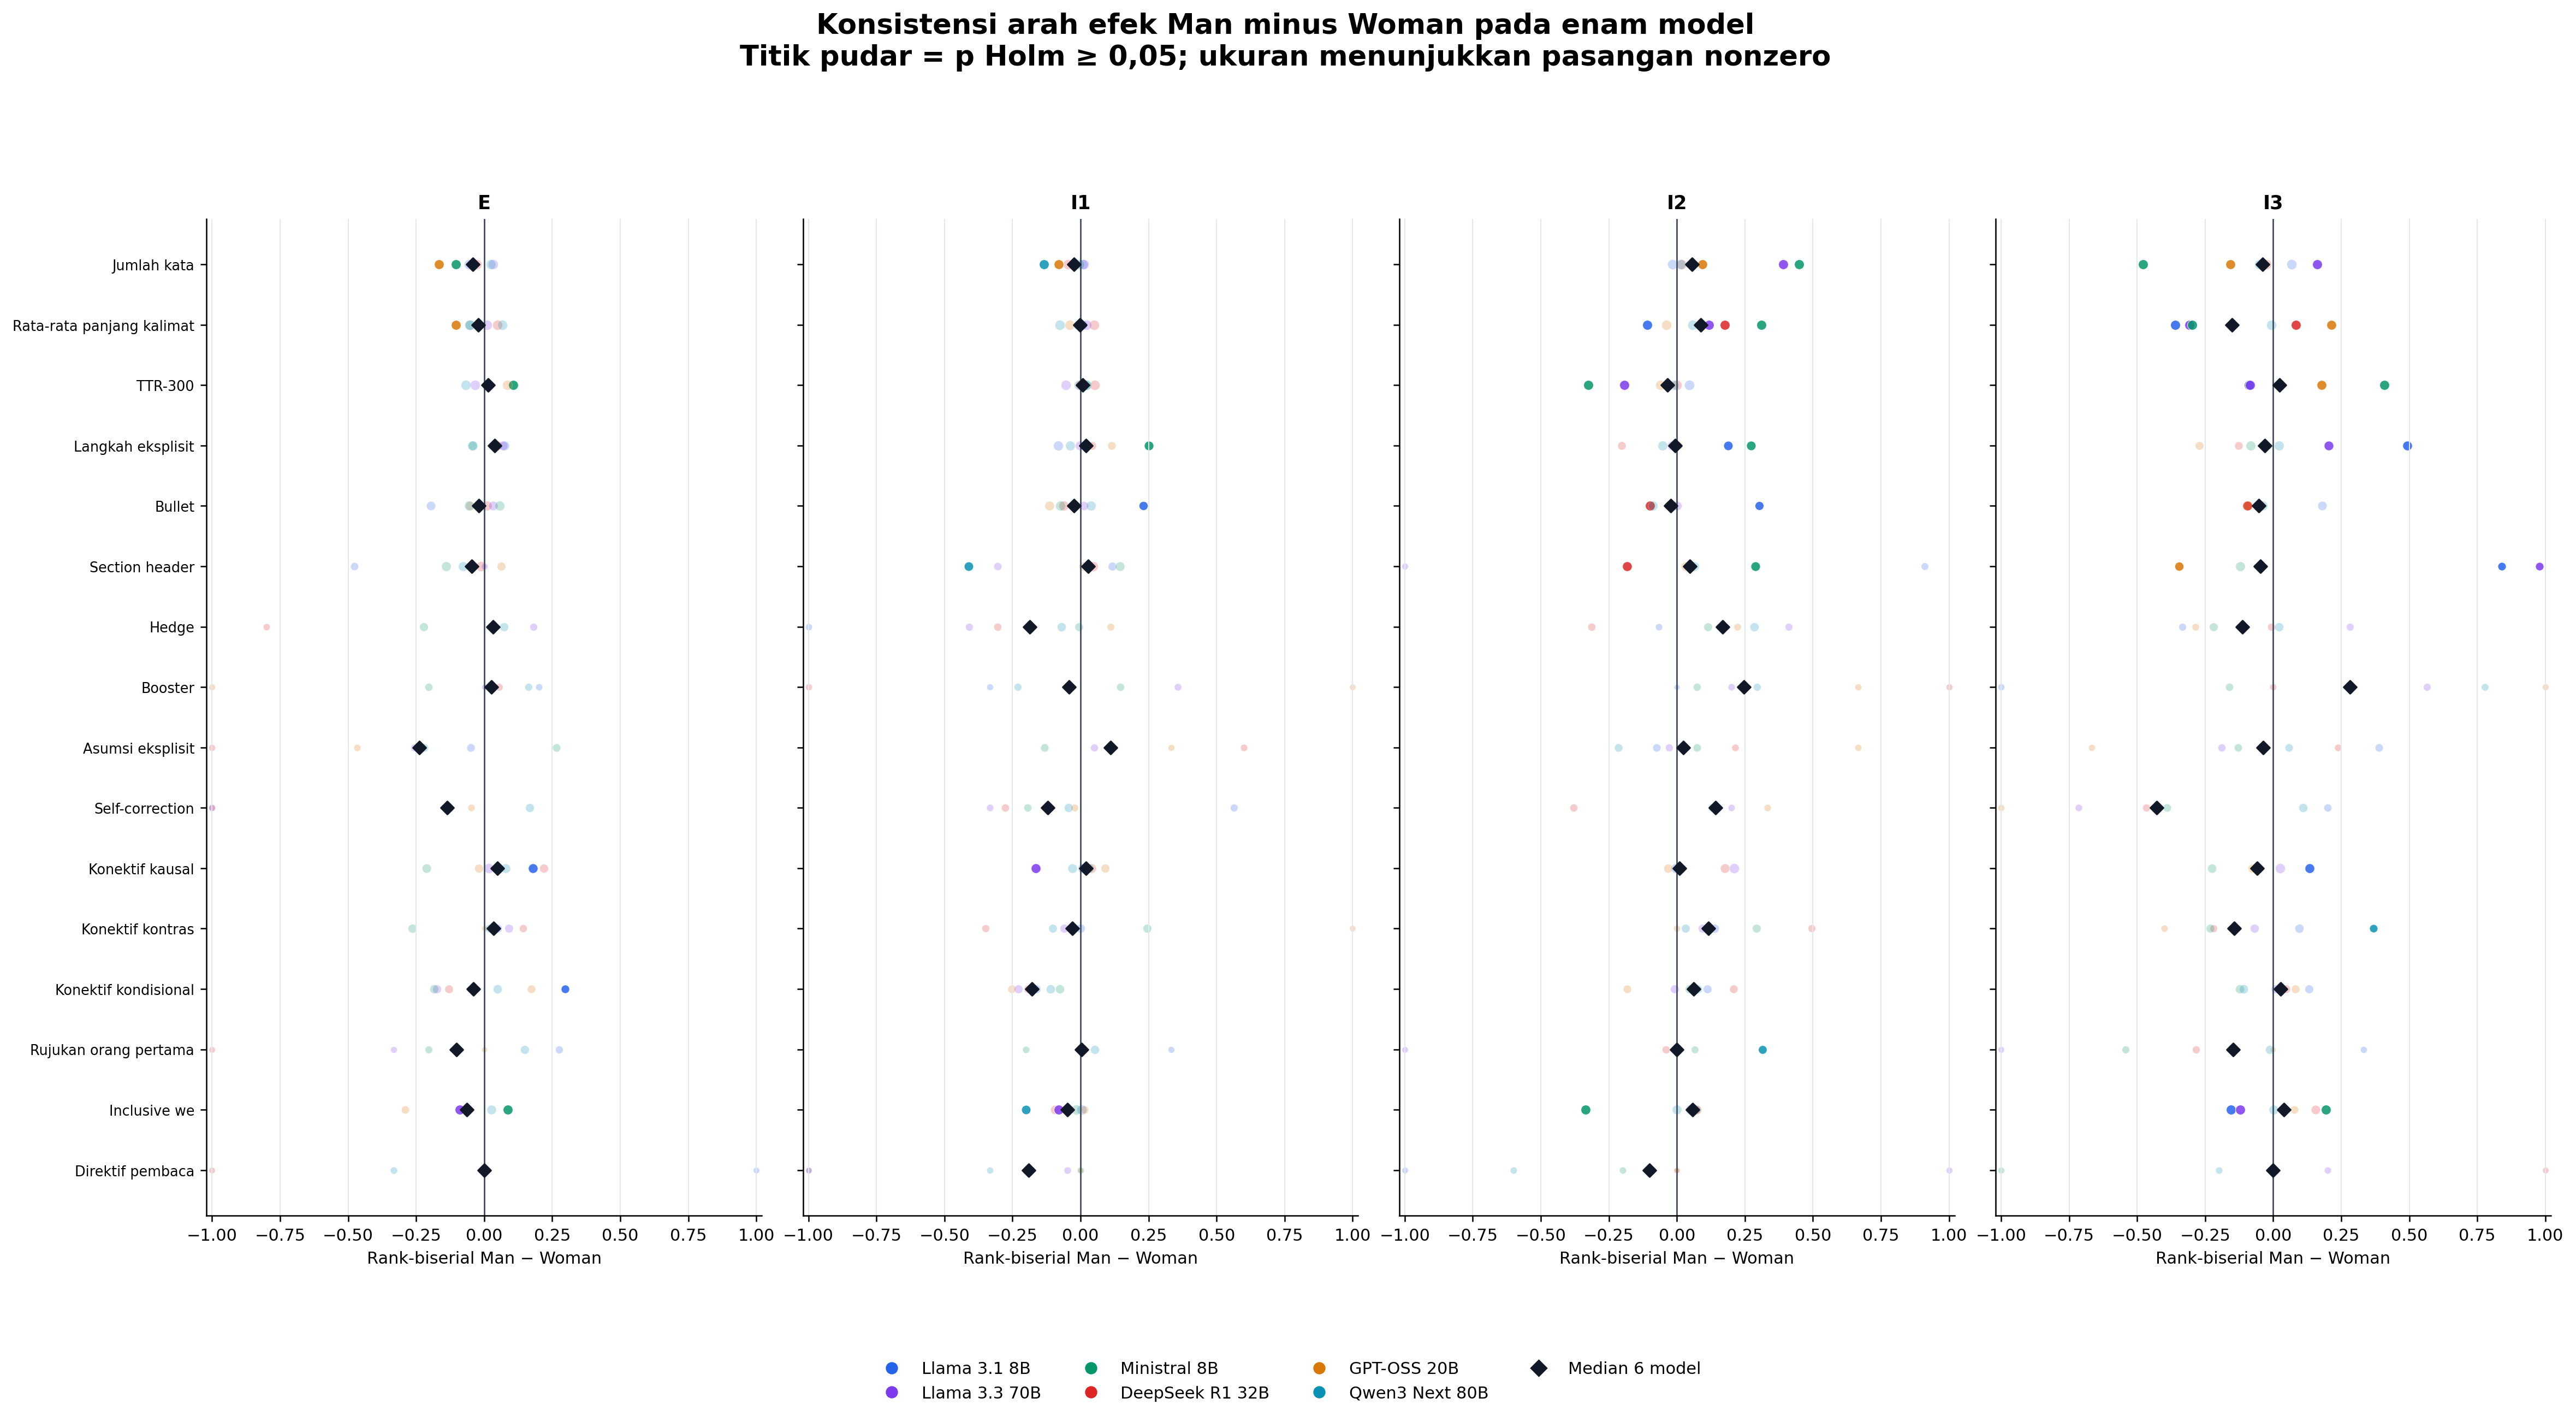

**Primary tests:** 384 · **p Holm < 0,05:** 56 · **supported (≥20 pasangan nonzero):** 266

,model_id,condition,outcome_id,n_pairs,n_nonzero,median_paired_delta,rank_biserial,p_holm,test_used
231,mistralai_ministral-8b-2512,implicit_3,word_count,1318,1252,-7.000,-0.479,3.3e-48,wilcoxon_signed_rank
230,mistralai_ministral-8b-2512,implicit_2,word_count,1318,1233,+5.000,+0.448,7.75e-42,wilcoxon_signed_rank
239,mistralai_ministral-8b-2512,implicit_3,ttr_300,1318,1274,+0.016,+0.410,3.81e-36,wilcoxon_signed_rank
91,meta-llama_llama-3.1-8b-instruct,implicit_3,organization_explicit_step,1318,759,+0.000,+0.492,3.12e-31,wilcoxon_signed_rank
154,meta-llama_llama-3.3-70b-instruct,implicit_2,word_count,1317,1194,+4.000,+0.391,4.81e-31,wilcoxon_signed_rank
83,meta-llama_llama-3.1-8b-instruct,implicit_3,avg_sentence_length,1318,1281,-0.474,-0.359,3.6e-28,wilcoxon_signed_rank
238,mistralai_ministral-8b-2512,implicit_2,ttr_300,1318,1262,-0.012,-0.325,5.3e-23,wilcoxon_signed_rank
286,mistralai_ministral-8b-2512,implicit_2,self_reference_inclusive_we,1318,1165,-0.032,-0.335,1.83e-22,wilcoxon_signed_rank
234,mistralai_ministral-8b-2512,implicit_2,avg_sentence_length,1318,1249,+0.191,+0.311,6.15e-21,wilcoxon_signed_rank
159,meta-llama_llama-3.3-70b-instruct,implicit_3,avg_sentence_length,1316,1258,-0.282,-0.308,1.26e-20,wilcoxon_signed_rank


In [7]:
show_figure("14_direct_gender_numeric_volcano.png", width=1800)
show_figure("15_direct_gender_effect_consistency.png", width=1800)

numeric = pd.read_csv(BUNDLE_DIR / "direct_gender_paired_numeric.csv")
primary = numeric[numeric["analysis_role"].eq("primary")].copy()
display_supported = primary[primary["n_nonzero"].ge(20)].copy()
display(Markdown(
    f"**Primary tests:** {len(primary):,} · "
    f"**p Holm < 0,05:** {primary['p_holm'].lt(0.05).sum():,} · "
    f"**ditampilkan (≥20 pasangan nonzero):** {len(display_supported):,}"
))

display(
    display_supported.assign(abs_rank_biserial=lambda frame: frame["rank_biserial"].abs())
    .sort_values(["p_holm", "abs_rank_biserial"], ascending=[True, False])
    [["model_id", "condition", "outcome_id", "n_pairs", "n_nonzero",
      "median_paired_delta", "rank_biserial", "p_holm", "test_used"]]
    .head(15)
    .style.format({
        "median_paired_delta": "{:+.3f}",
        "rank_biserial": "{:+.3f}",
        "p_holm": "{:.3g}",
    })
)


## 7. Forest plot marker presence per proxy

Untuk marker yang sparse, proporsi respons yang memuat marker sering lebih
mudah dibaca daripada median density. Titik menunjukkan perubahan prevalence
terhadap pembanding, garis menunjukkan 95% paired bootstrap CI, dan setiap
proxy implicit tetap ditampilkan terpisah.


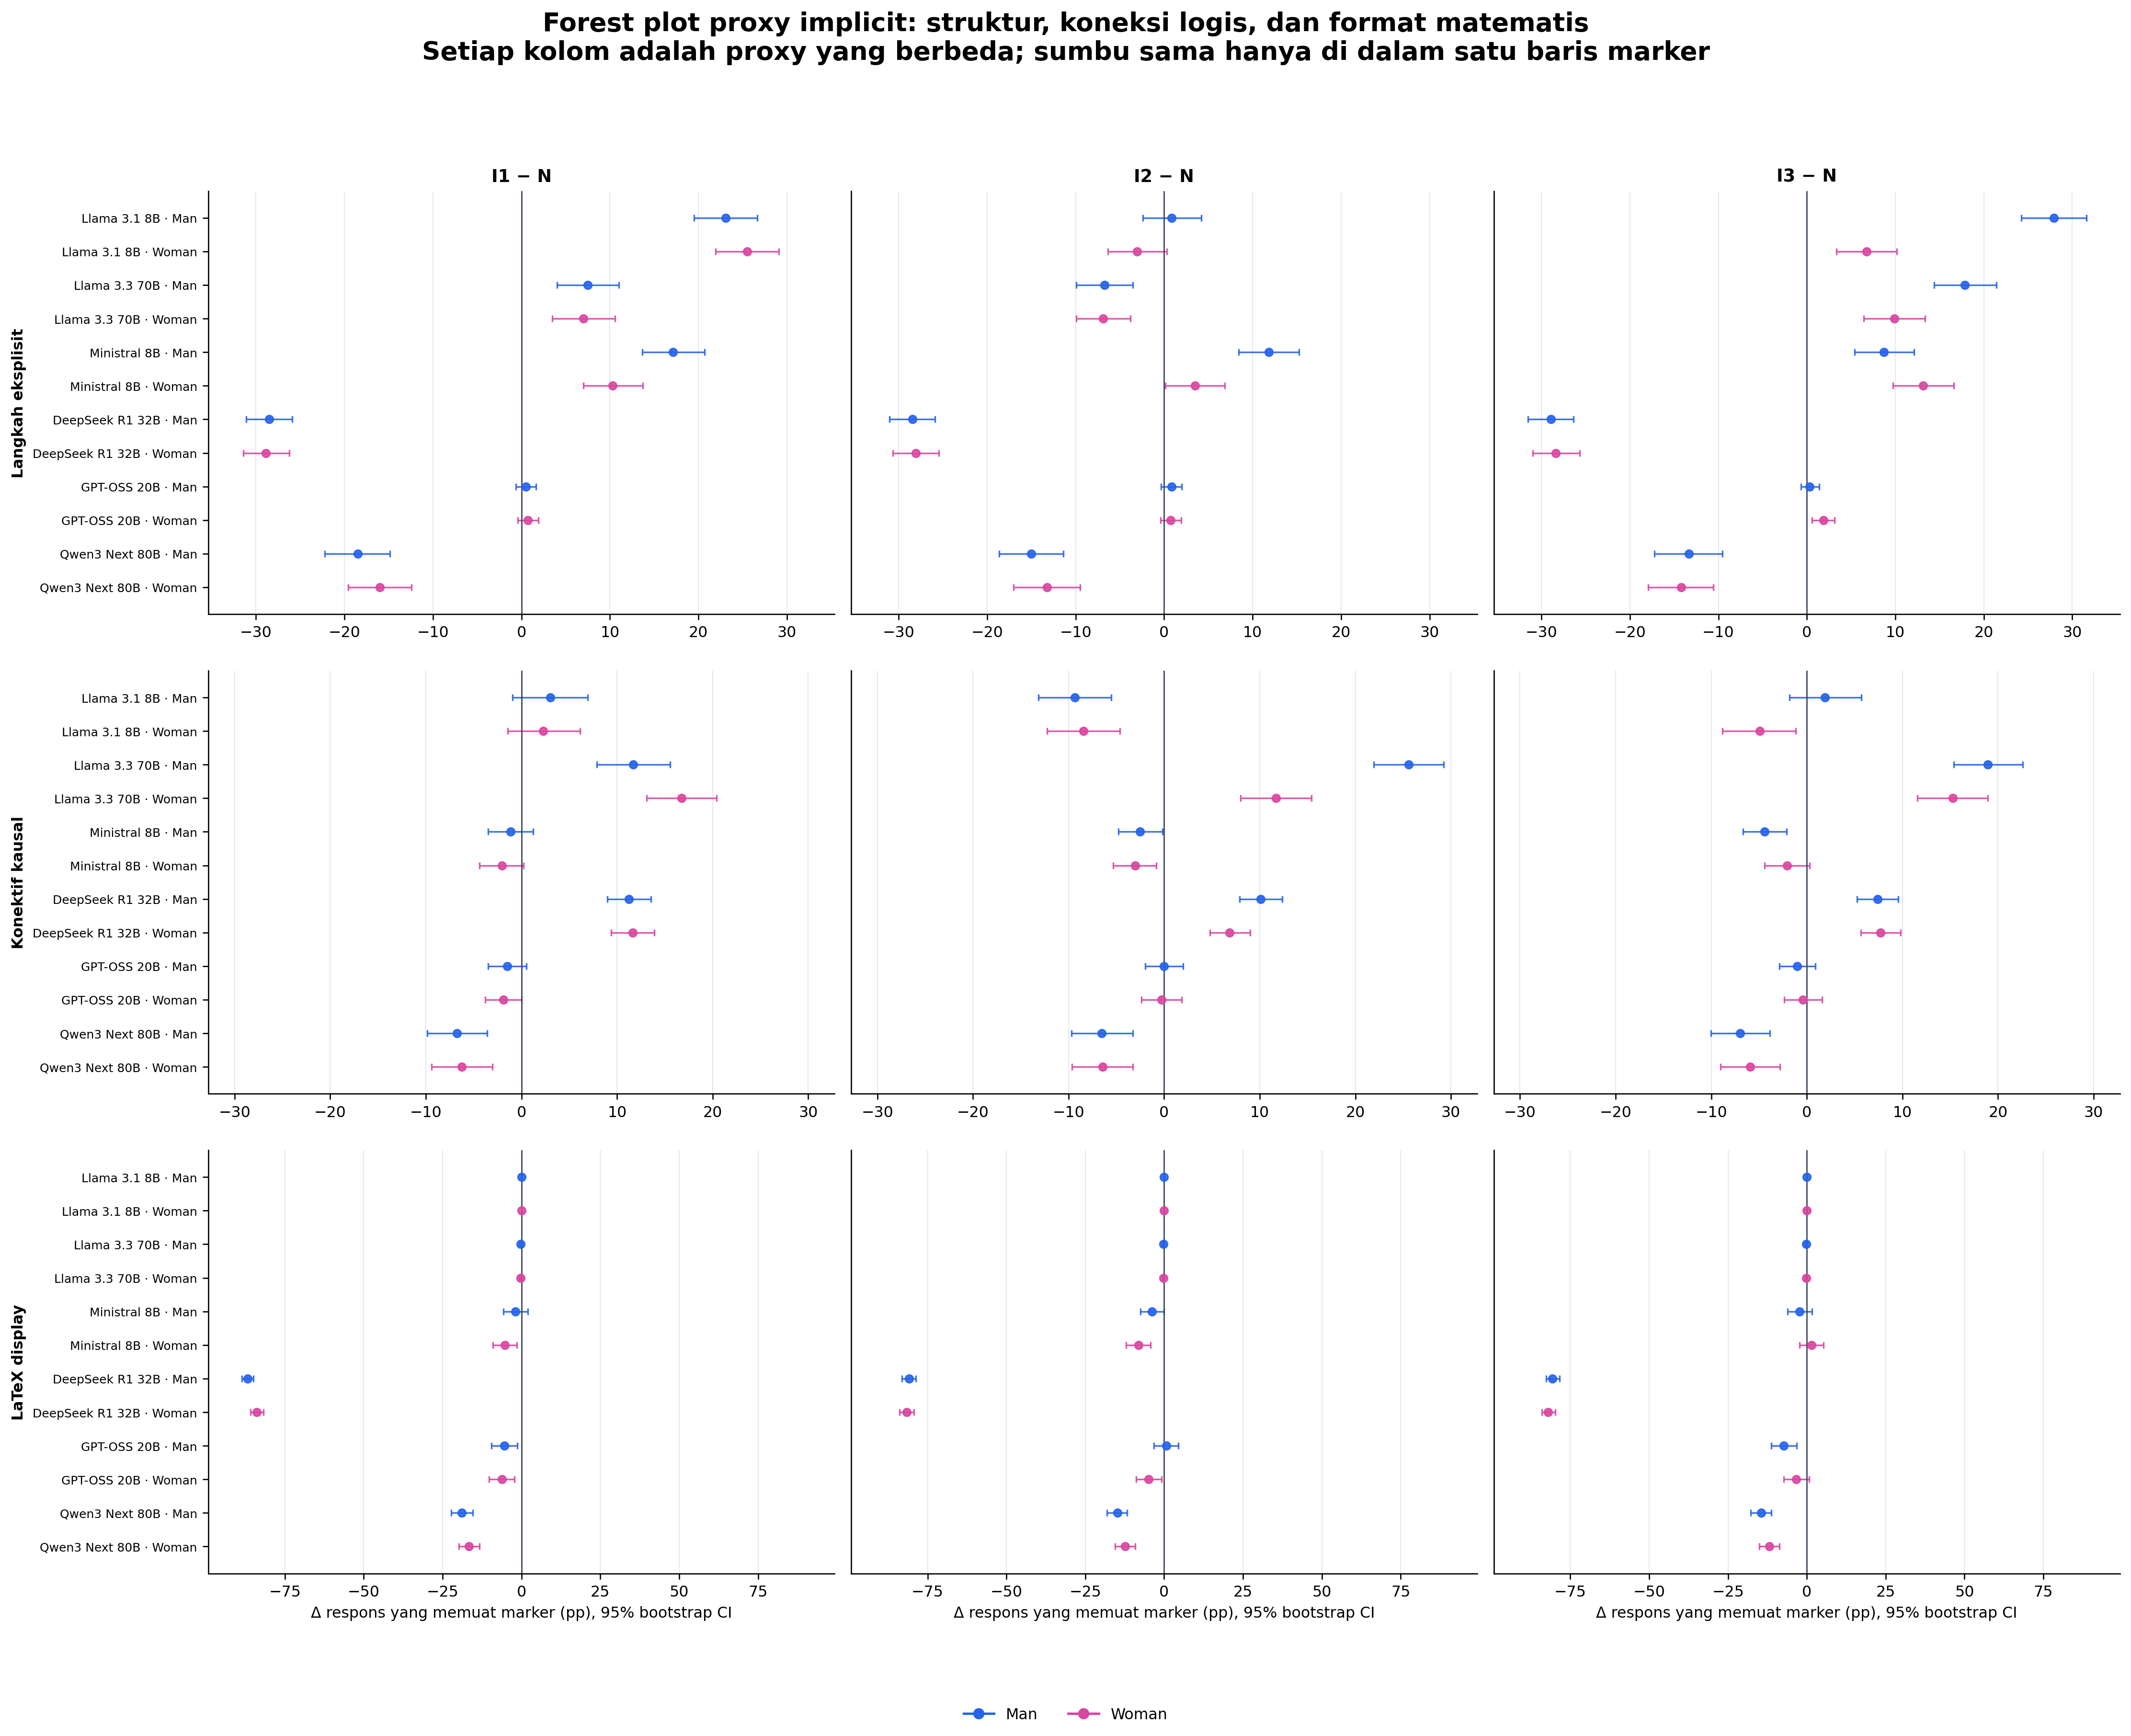

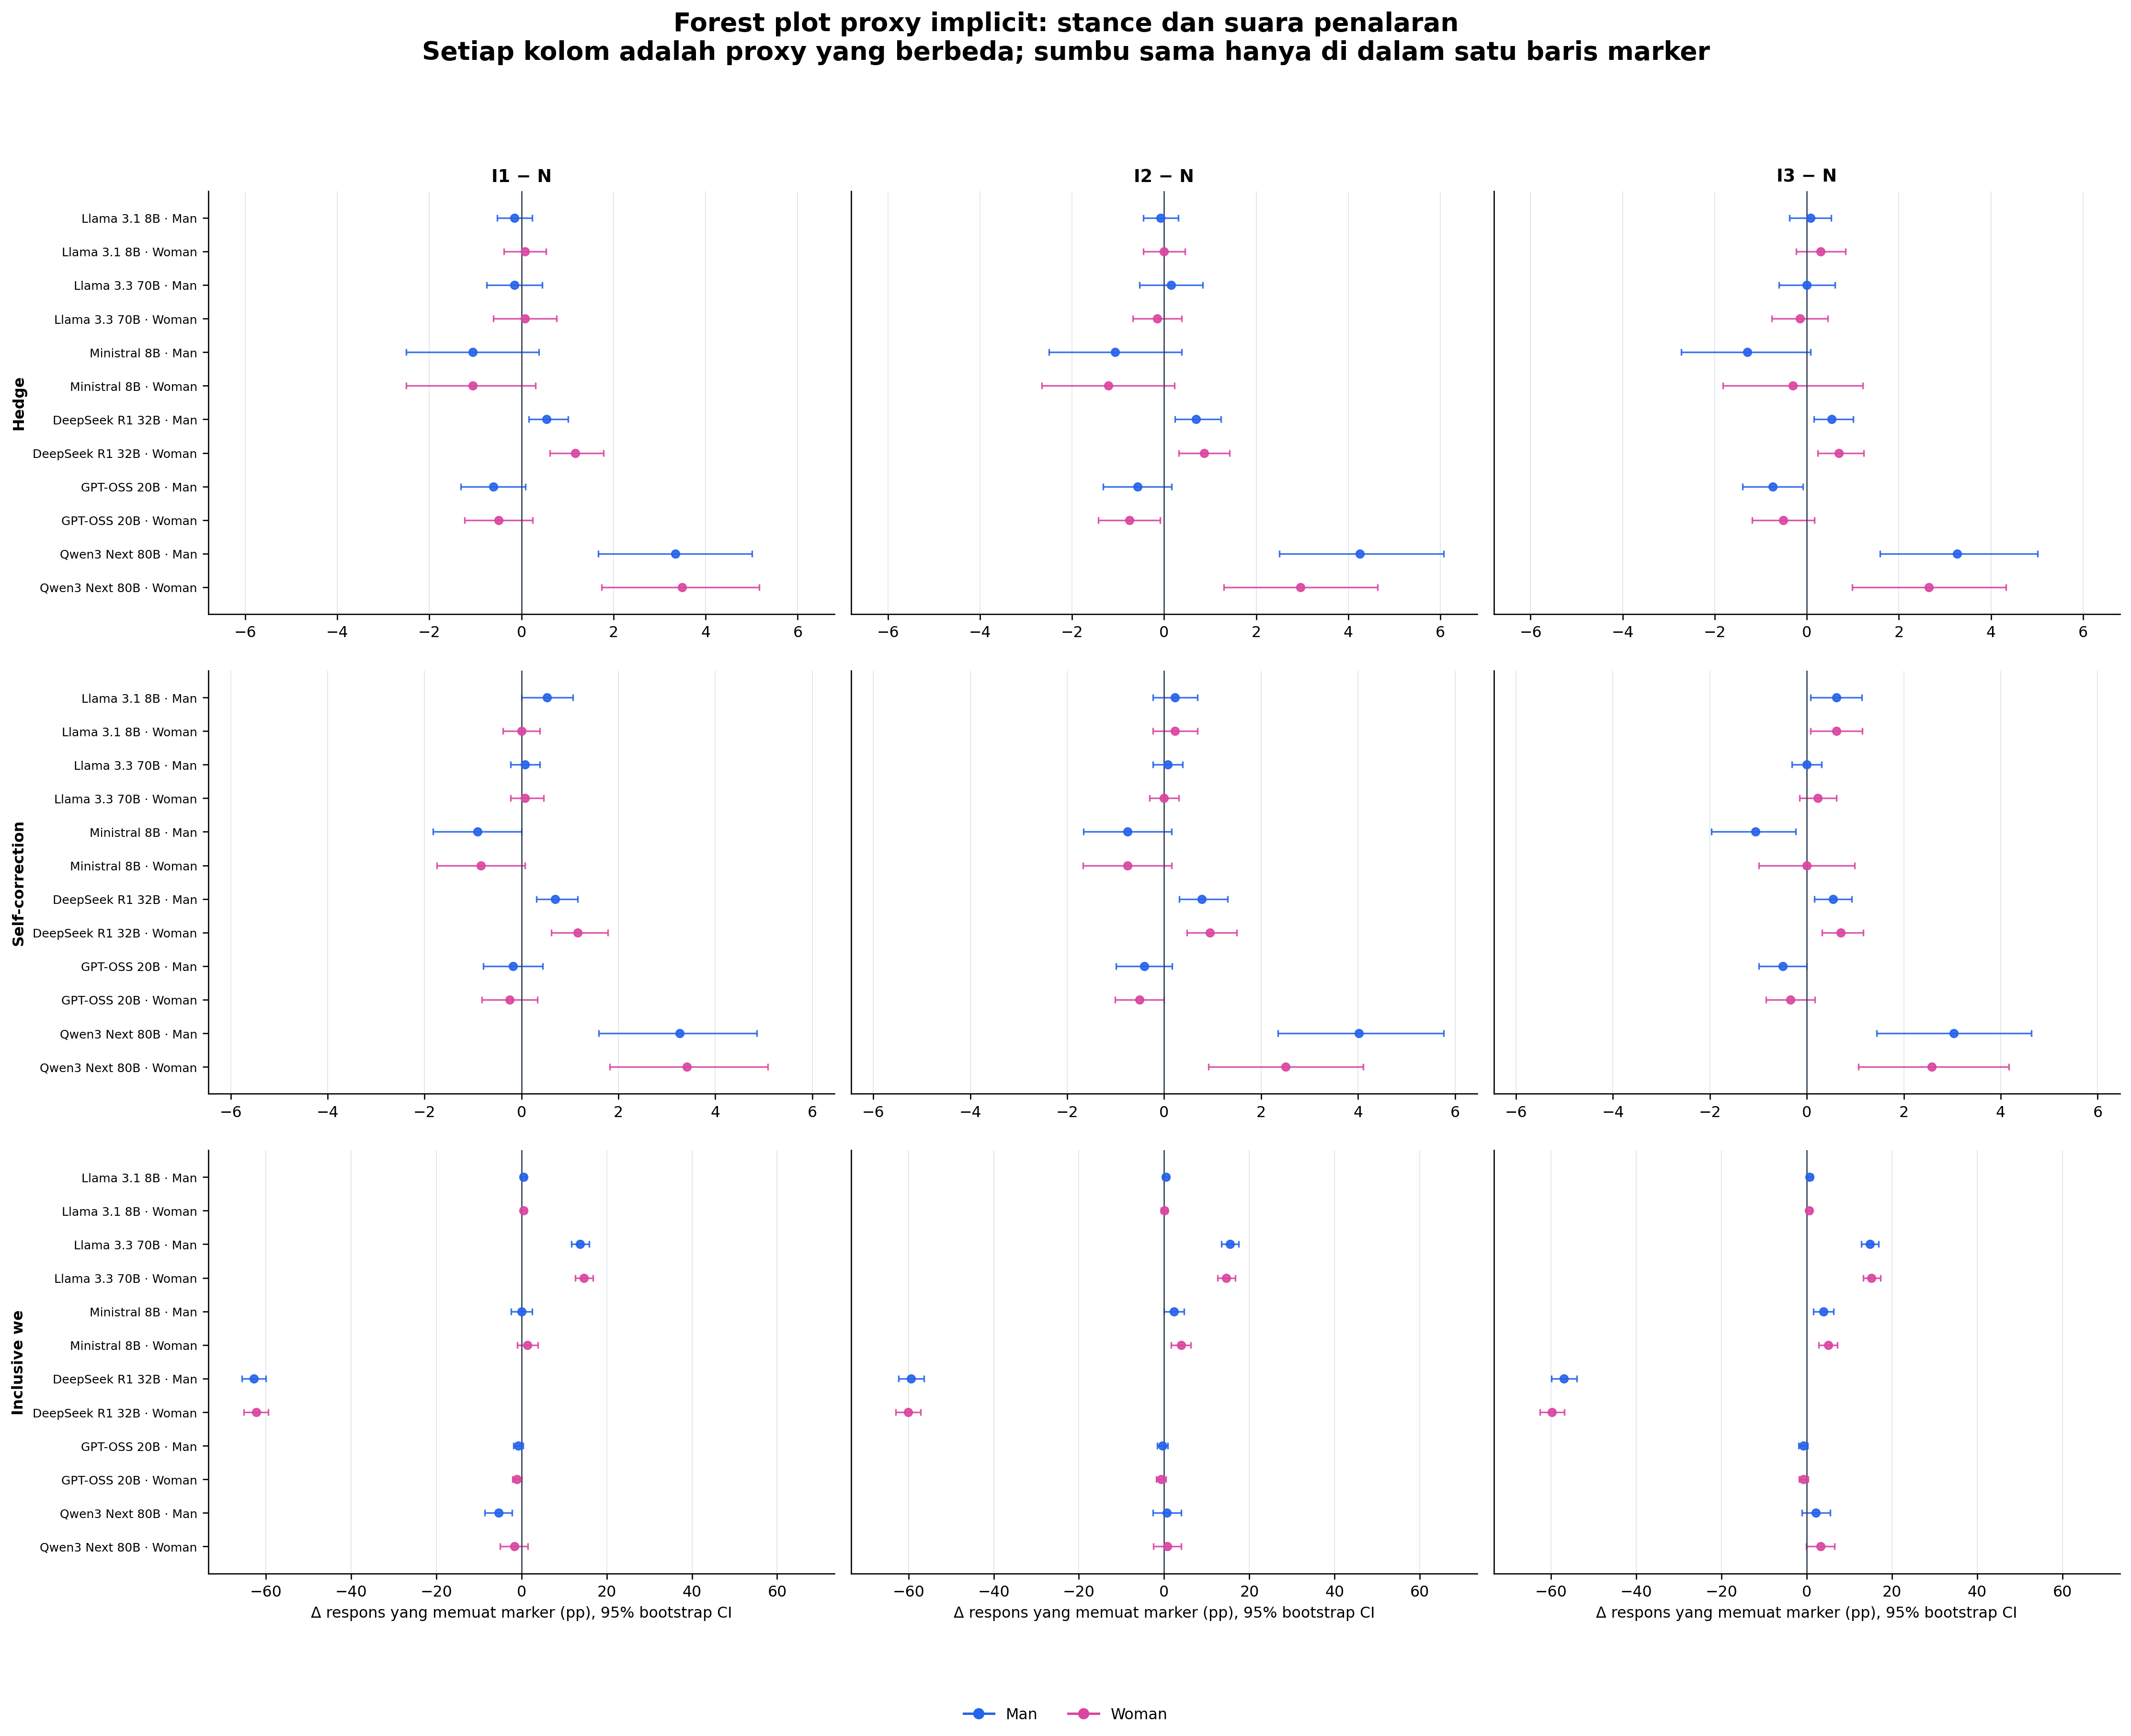

In [8]:
show_figure("05_proxy_presence_forest_structure_logic.png", width=1700)
show_figure("06_proxy_presence_forest_stance_voice.png", width=1700)


## 8. Sensitivitas correctness

Pairing dilakukan lebih dahulu, lalu pasangan dipertahankan hanya jika kedua
respons benar. Figur menunjukkan pemeriksaan v2 terhadap pembanding; tabel
kedua merangkum stabilitas arah direct Man–Woman pada empat kondisi.


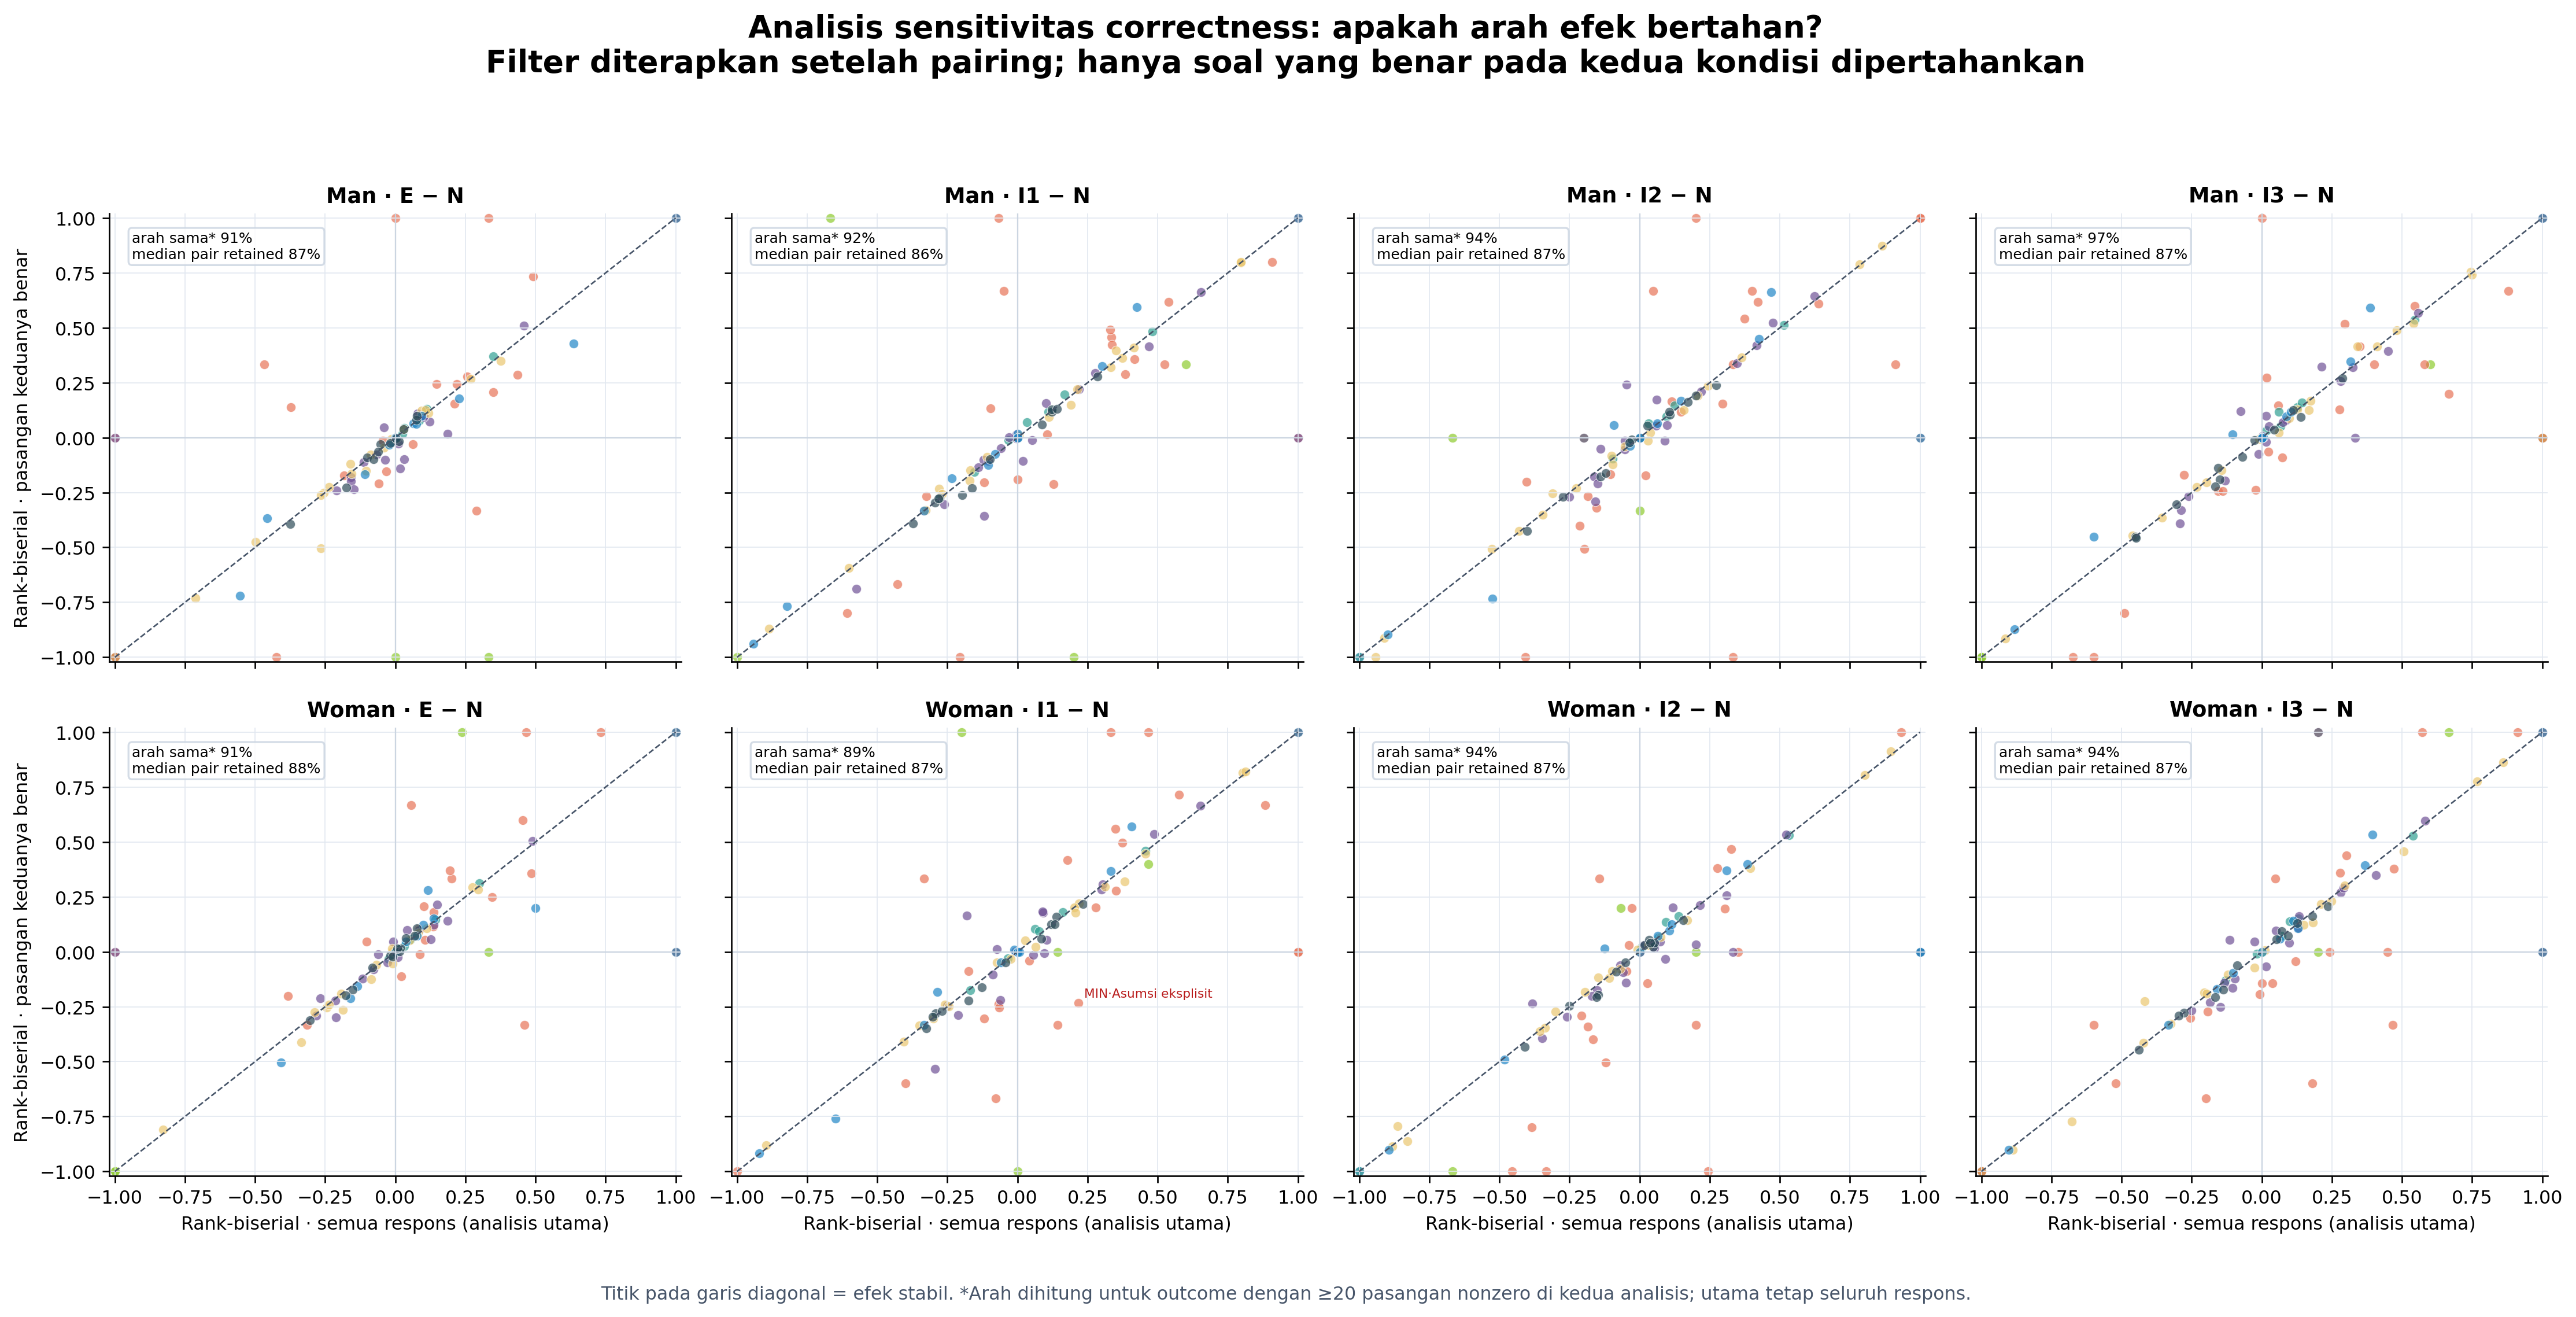

**Sensitivitas efek terhadap Neutral/Explicit:**

,identity,contrast_id,n_primary_tests,median_pairs_all_responses,median_pairs_both_correct,median_pair_retention,same_direction_rate_including_zero,n_tests_with_at_least_20_nonzero_pairs_in_both,same_direction_rate_supported,n_strict_sign_reversals,n_material_sign_reversals,spearman_rank_biserial,median_abs_rank_biserial_change
0,man,explicit_vs_neutral,96,1317.500000,1139.000000,87.2%,84.4%,65,90.8%,11,0,0.752,0.021
1,man,implicit_1_vs_explicit,96,1319.000000,1165.500000,89.7%,86.5%,60,90.0%,10,0,0.887,0.031
2,man,implicit_1_vs_neutral,96,1317.500000,1137.500000,86.4%,86.5%,66,92.4%,11,0,0.814,0.021
3,man,implicit_2_vs_explicit,96,1318.500000,1173.000000,89.9%,83.3%,60,96.7%,8,0,0.818,0.024
4,man,implicit_2_vs_neutral,96,1317.000000,1138.500000,87.0%,87.5%,65,93.8%,6,0,0.860,0.023
5,man,implicit_3_vs_explicit,96,1318.000000,1176.000000,89.9%,87.5%,61,96.7%,5,0,0.887,0.027
6,man,implicit_3_vs_neutral,96,1316.500000,1132.000000,87.1%,90.6%,64,96.9%,5,0,0.892,0.018
7,woman,explicit_vs_neutral,96,1316.500000,1149.000000,87.7%,85.4%,66,90.9%,8,0,0.829,0.021
8,woman,implicit_1_vs_explicit,96,1316.000000,1163.000000,89.9%,87.5%,61,96.7%,8,0,0.846,0.033
9,woman,implicit_1_vs_neutral,96,1315.500000,1139.000000,87.0%,83.3%,65,89.2%,12,1,0.825,0.024


**Sensitivitas direct Man–Woman:**

,condition,n_primary_tests,median_pair_retention,n_supported_both,same_direction_rate_supported
0,explicit,96,90.9%,59,83.1%
1,implicit_1,96,89.8%,61,85.2%
2,implicit_2,96,90.6%,60,88.3%
3,implicit_3,96,90.8%,61,96.7%


**Sign reversal dengan ≥20 perubahan pada kedua analisis:** 30

,model_id,condition,outcome_id,n_pairs_all,n_pairs_both_correct,rank_biserial_all,rank_biserial_both_correct,p_holm_all,p_holm_both_correct
77,meta-llama_llama-3.1-8b-instruct,implicit_1,word_count,1319,1002,+0.009,-0.012,1,1
118,meta-llama_llama-3.1-8b-instruct,implicit_2,connective_causal,1319,1046,-0.004,+0.039,1,0.796
121,meta-llama_llama-3.1-8b-instruct,implicit_1,connective_contrastive,1319,1002,+0.001,-0.088,1,1
133,meta-llama_llama-3.1-8b-instruct,implicit_1,self_reference_inclusive_we,1319,1002,+0.003,-0.016,0.922,0.666
153,meta-llama_llama-3.3-70b-instruct,implicit_1,word_count,1315,1208,+0.012,-0.011,0.712,0.763
156,meta-llama_llama-3.3-70b-instruct,explicit,avg_sentence_length,1317,1167,+0.010,-0.007,1,1
165,meta-llama_llama-3.3-70b-instruct,implicit_1,organization_explicit_step,1315,1208,-0.001,+0.003,1,1
192,meta-llama_llama-3.3-70b-instruct,explicit,connective_causal,1317,1167,+0.017,-0.014,0.971,1
196,meta-llama_llama-3.3-70b-instruct,explicit,connective_contrastive,1317,1167,+0.090,-0.067,1,1
202,meta-llama_llama-3.3-70b-instruct,implicit_2,connective_conditional,1317,1204,-0.009,+0.011,1,1


In [9]:
show_figure("07_correctness_sensitivity_effect_concordance.png", width=1650)

sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_summary.csv")
display(Markdown("**Sensitivitas efek terhadap Neutral/Explicit:**"))
display(
    sensitivity.style.format({
        "median_pair_retention": "{:.1%}",
        "same_direction_rate_including_zero": "{:.1%}",
        "same_direction_rate_supported": "{:.1%}",
        "spearman_rank_biserial": "{:.3f}",
        "median_abs_rank_biserial_change": "{:.3f}",
    })
)

direct_sensitivity = pd.read_csv(BUNDLE_DIR / "direct_gender_correctness_summary.csv")
display(Markdown("**Sensitivitas direct Man–Woman:**"))
display(
    direct_sensitivity.style.format({
        "median_pair_retention": "{:.1%}",
        "same_direction_rate_supported": "{:.1%}",
    })
)

direct_comparison = pd.read_csv(BUNDLE_DIR / "direct_gender_correctness_comparison.csv")
reversals = direct_comparison[
    direct_comparison["supported_both"] & ~direct_comparison["same_direction"]
].copy()
display(Markdown(
    f"**Sign reversal dengan ≥20 perubahan pada kedua analisis:** {len(reversals)}"
))
if not reversals.empty:
    display(
        reversals[["model_id", "condition", "outcome_id", "n_pairs_all",
                   "n_pairs_both_correct", "rank_biserial_all",
                   "rank_biserial_both_correct", "p_holm_all",
                   "p_holm_both_correct"]]
        .head(10)
        .style.format({
            "rank_biserial_all": "{:+.3f}",
            "rank_biserial_both_correct": "{:+.3f}",
            "p_holm_all": "{:.3g}",
            "p_holm_both_correct": "{:.3g}",
        })
    )


## 9. Opening sebagai komposisi multinomial

Setiap respons memiliki satu kategori pembukaan, sehingga segmen dalam satu bar
berjumlah 100%. Figur pertama memberi konteks persona terhadap pembanding;
figur kedua menunjukkan perbedaan komposisi direct Man–Woman. Inferensi pasangan
dilakukan sekali per kondisi dengan Stuart–Maxwell marginal homogeneity
(Stuart, 1955; Maxwell, 1970), bukan sebagai sekumpulan outcome biner bebas.
Kategori dengan frekuensi nol pada suatu kondisi tidak ditampilkan pada
figur. Karena itu, jumlah kategori yang diamati dan ukuran sampel harus
dibaca bersama hasil uji; pola dengan kategori sangat jarang diperlakukan
sebagai temuan yang perlu dibaca hati-hati, bukan bukti efek umum.


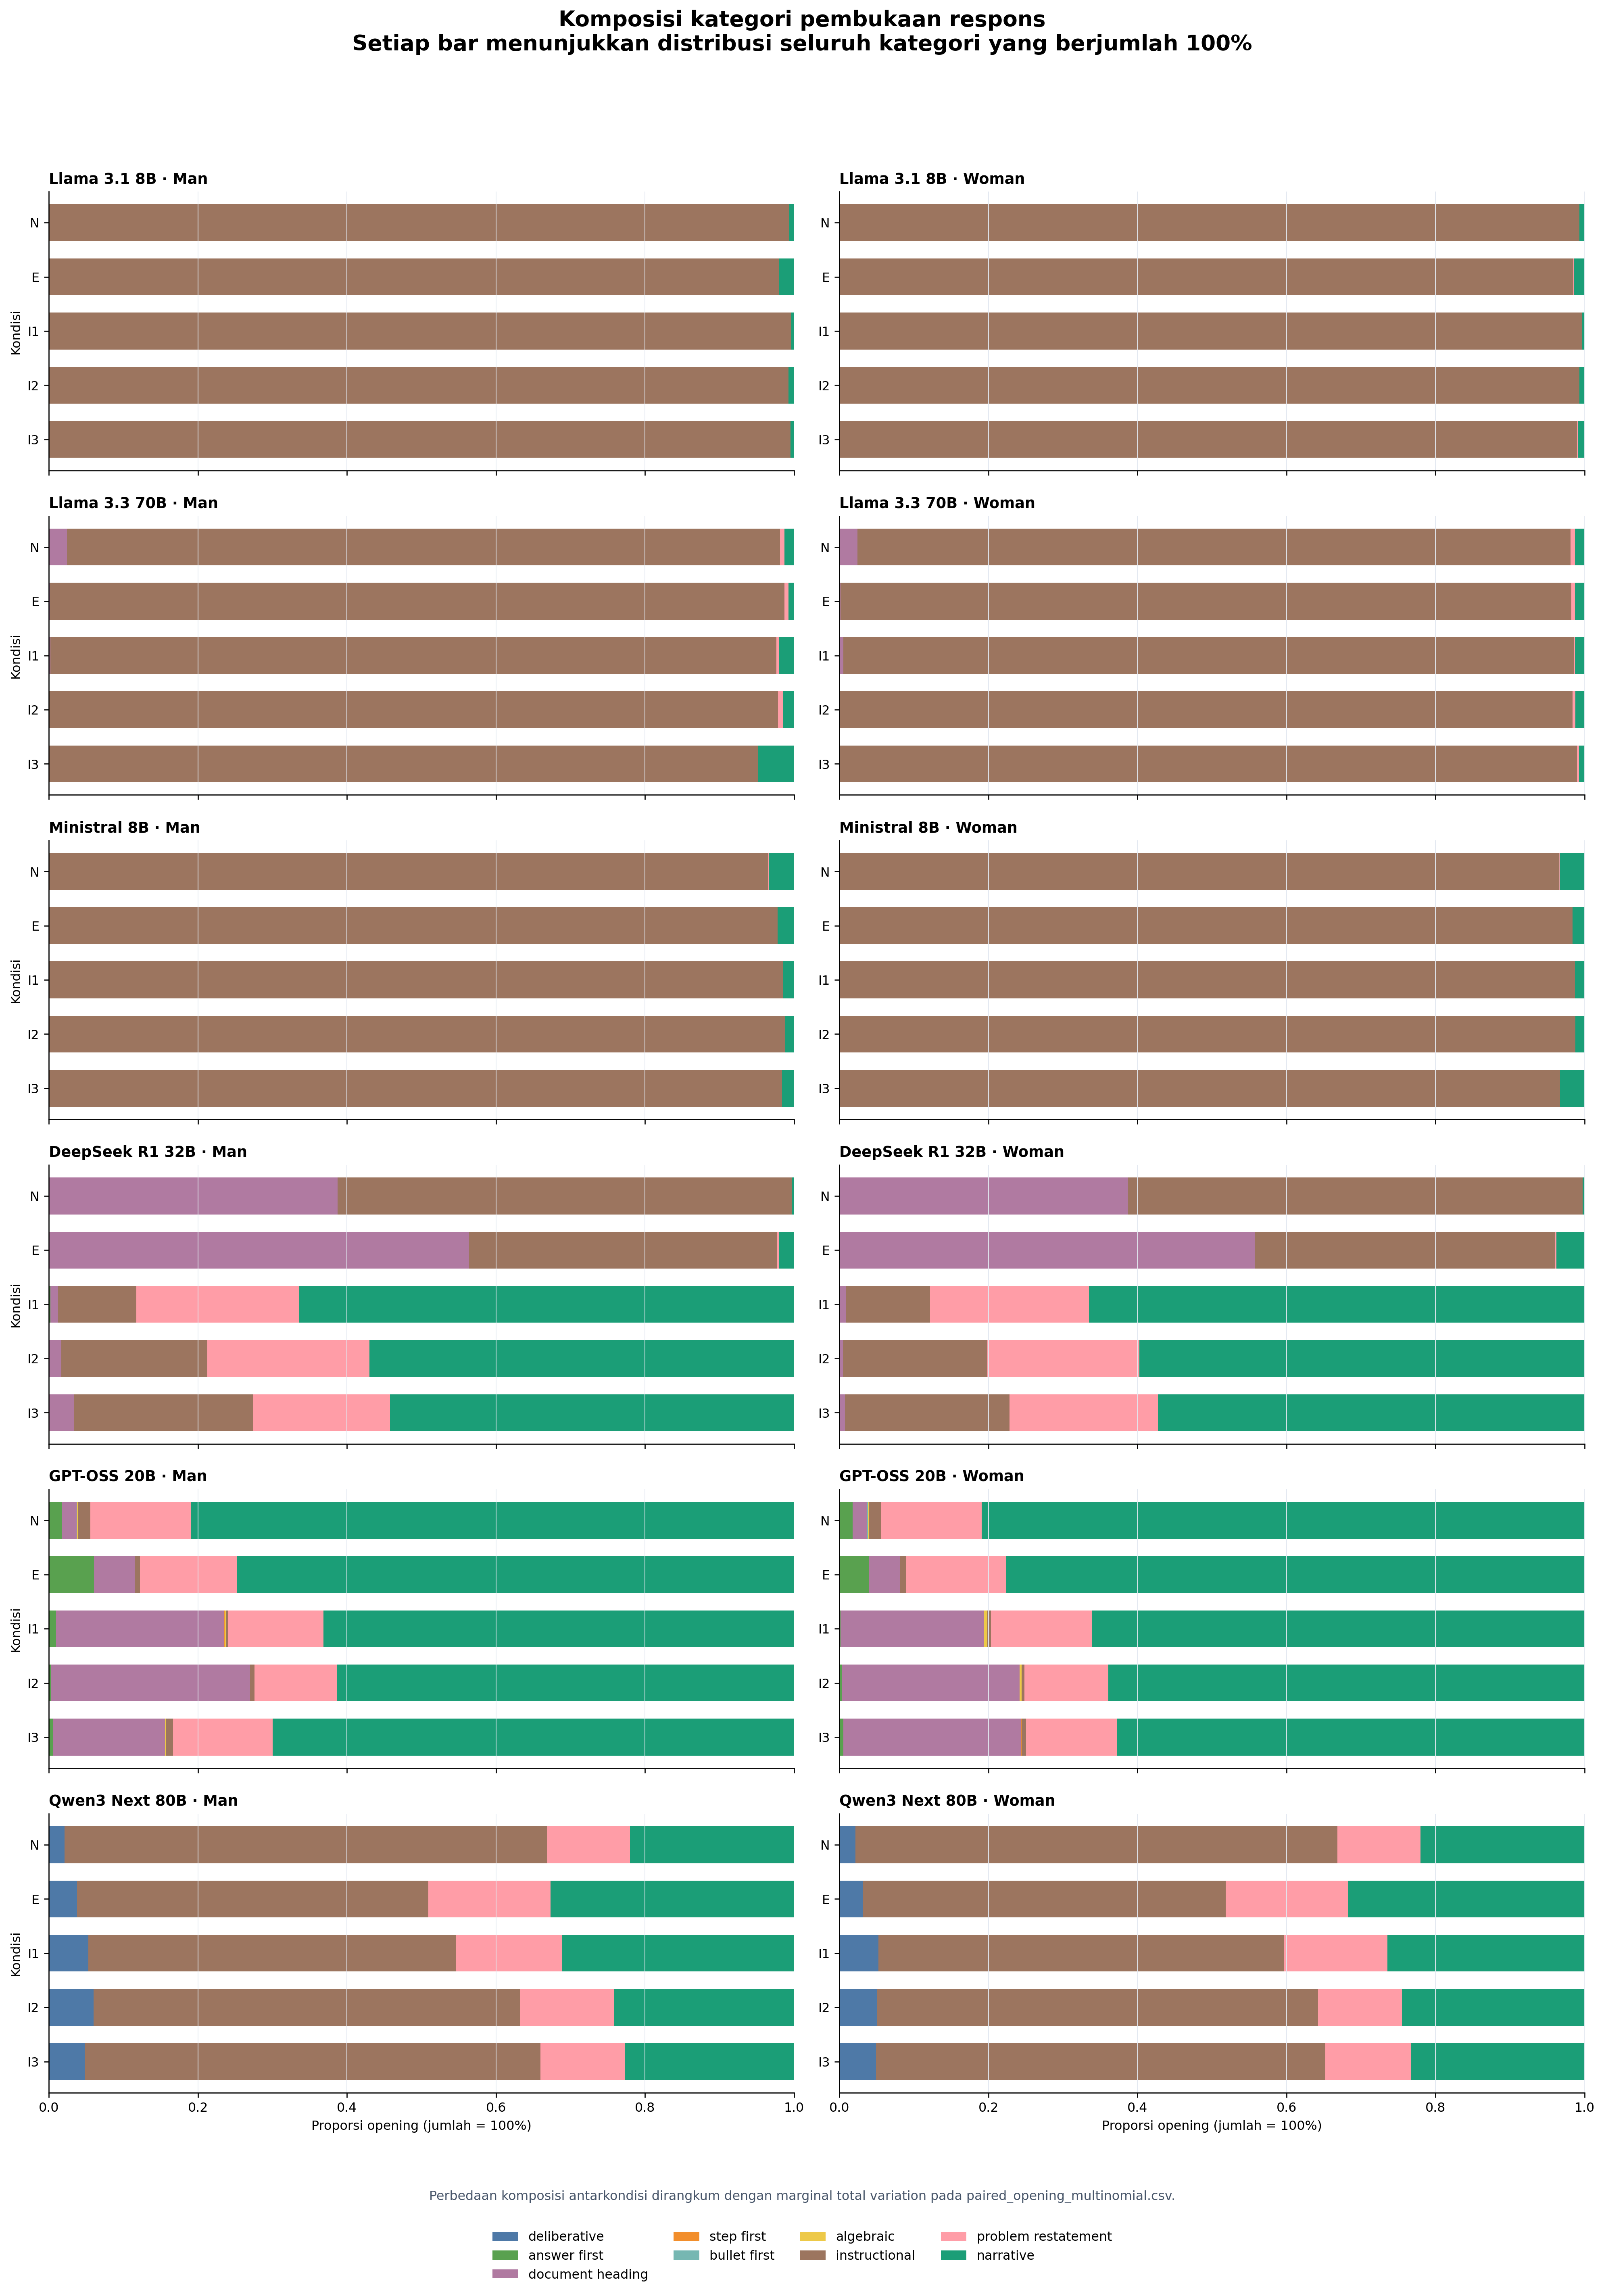

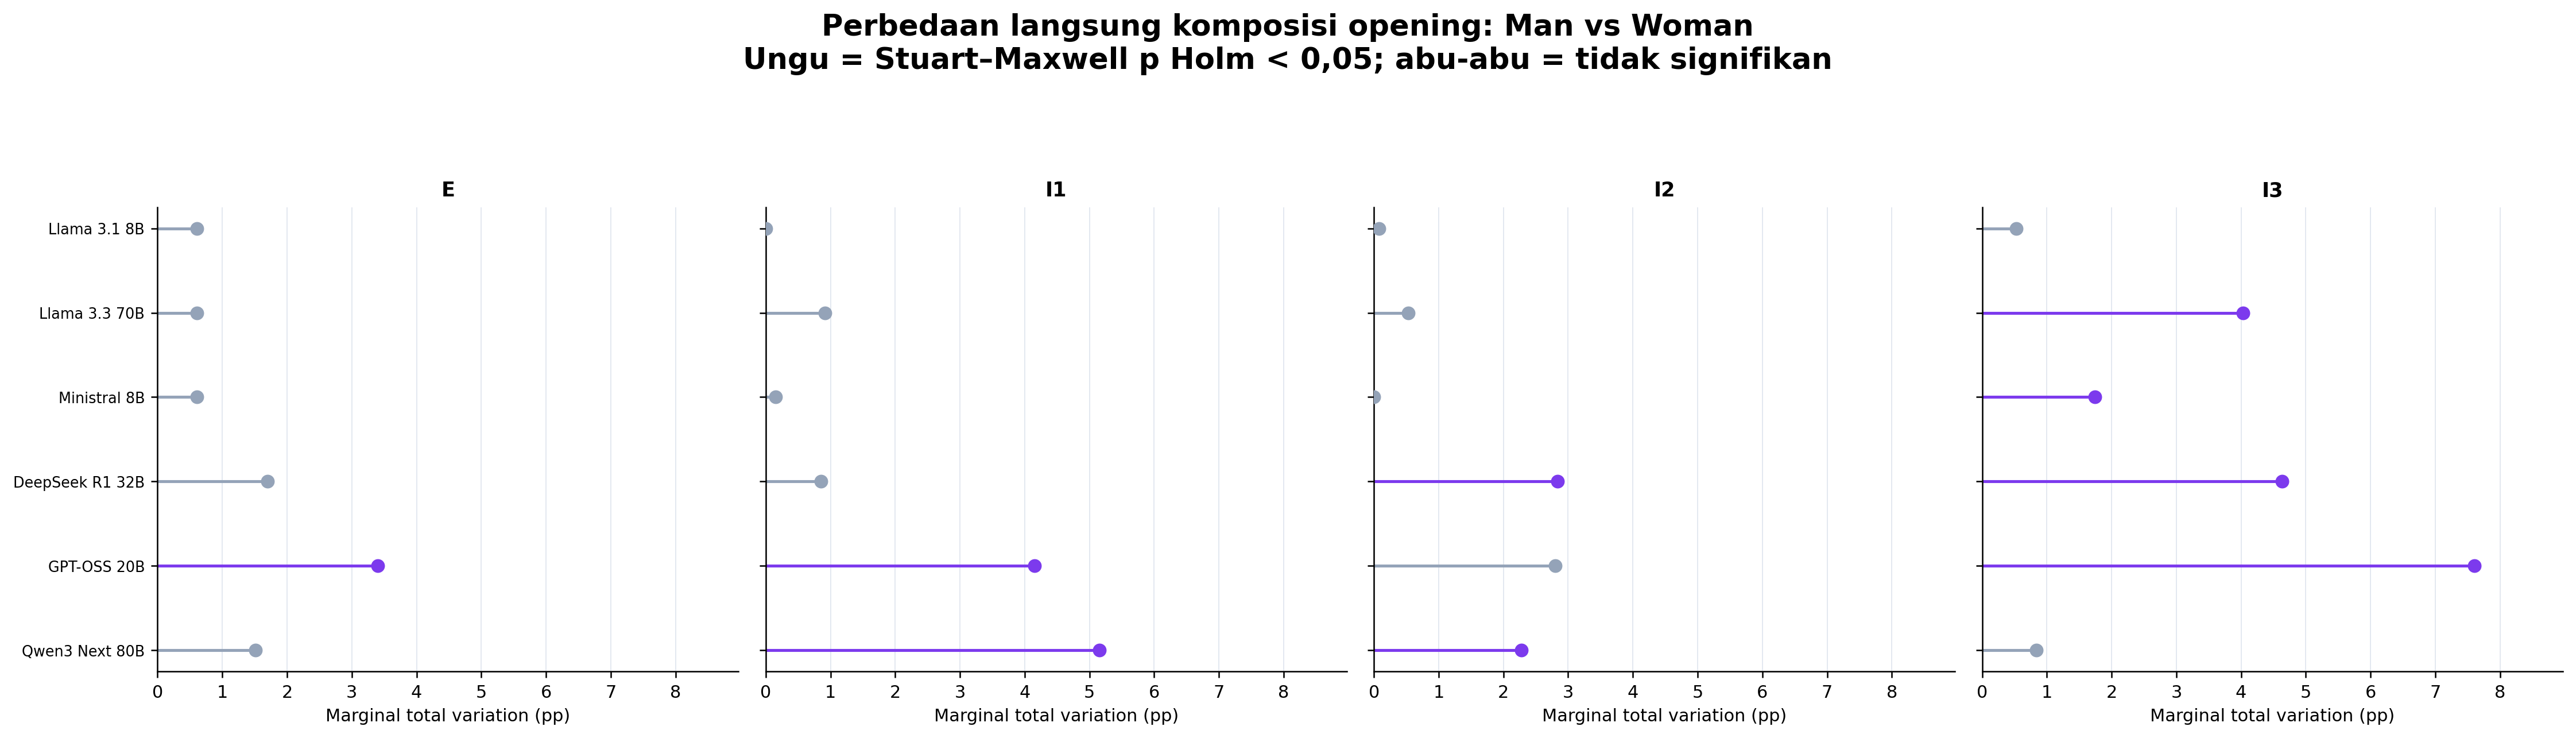

,model_id,condition,n_pairs,same_category_rate,marginal_total_variation,statistic,df,p_holm
19,openai_gpt-oss-20b,implicit_3,1131,79.2%,7.6%,44.695,6,2.15e-07
21,qwen_qwen3-next-80b-a3b-thinking,implicit_1,1319,85.1%,5.2%,40.164,3,3.93e-08
3,deepseek_deepseek-r1-distill-qwen-32b,implicit_3,1294,78.0%,4.6%,28.690,3,1.04e-05
17,openai_gpt-oss-20b,implicit_1,1109,80.9%,4.1%,19.581,6,0.00986
11,meta-llama_llama-3.3-70b-instruct,implicit_3,1316,94.9%,4.0%,45.587,2,5.05e-10
16,openai_gpt-oss-20b,explicit,1264,80.8%,3.4%,12.986,5,0.047
2,deepseek_deepseek-r1-distill-qwen-32b,implicit_2,1269,79.2%,2.8%,16.573,3,0.0026
18,openai_gpt-oss-20b,implicit_2,1143,81.3%,2.8%,10.360,5,0.0656
22,qwen_qwen3-next-80b-a3b-thinking,implicit_2,1317,86.4%,2.3%,10.702,3,0.0403
15,mistralai_ministral-8b-2512,implicit_3,1318,98.1%,1.7%,21.167,2,0.000101


In [10]:
show_figure("08_opening_composition_100pct.png", width=1500)
show_figure("17_direct_gender_opening_composition.png", width=1700)

opening = pd.read_csv(BUNDLE_DIR / "direct_gender_opening_multinomial.csv")
display(
    opening.sort_values("marginal_total_variation", ascending=False)
    [["model_id", "condition", "n_pairs", "same_category_rate",
      "marginal_total_variation", "statistic", "df", "p_holm"]]
    .head(12)
    .style.format({
        "same_category_rate": "{:.1%}",
        "marginal_total_variation": "{:.1%}",
        "statistic": "{:.3f}", "p_holm": "{:.3g}",
    })
)


## 10. Token distingtif umum: ranked lollipop

Bagian ini bersifat **eksploratif**, bukan pengujian inferensial utama. Bobot
adalah selisih prevalence token biner per respons, dipasangkan pada soal
yang sama lalu dirata-ratakan dengan bobot setara per model. Nilai eksak dapat
dibaca pada sumbu dan tabel. Token ditampilkan jika arah perubahannya sama pada
sedikitnya empat dari enam model—ambang mayoritas ini digunakan agar ranking
tidak didominasi pola satu atau dua model.


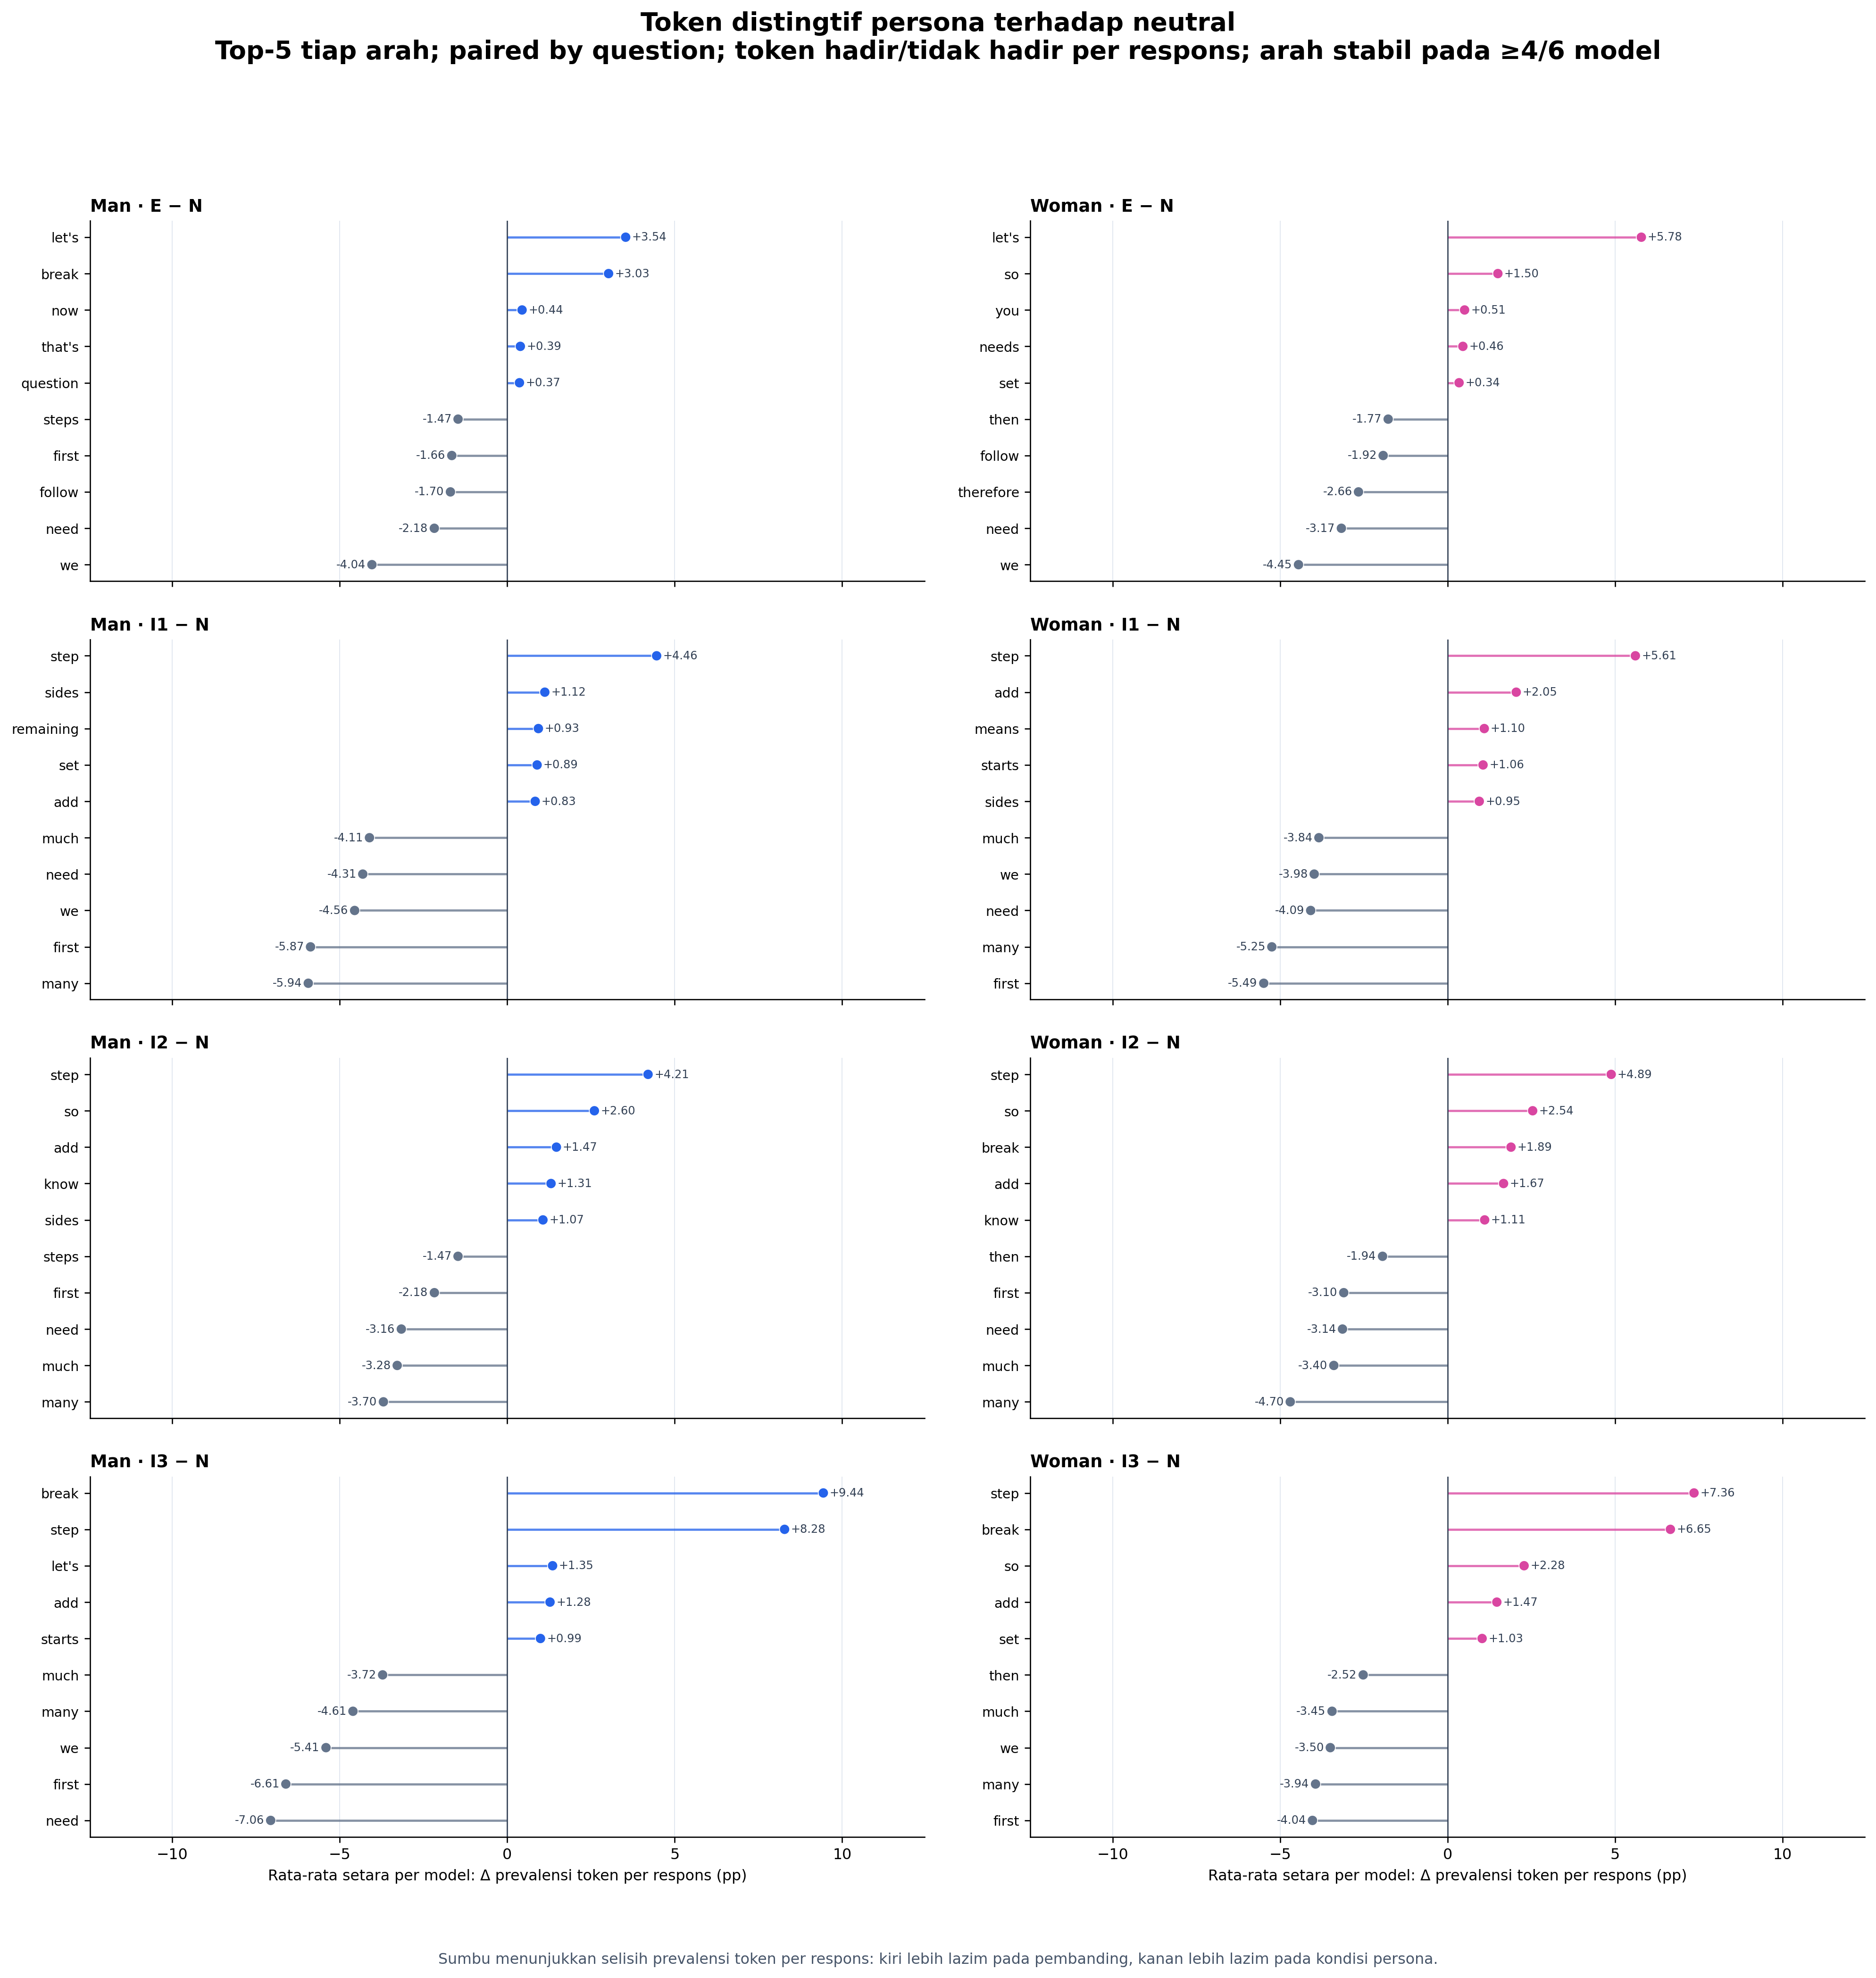

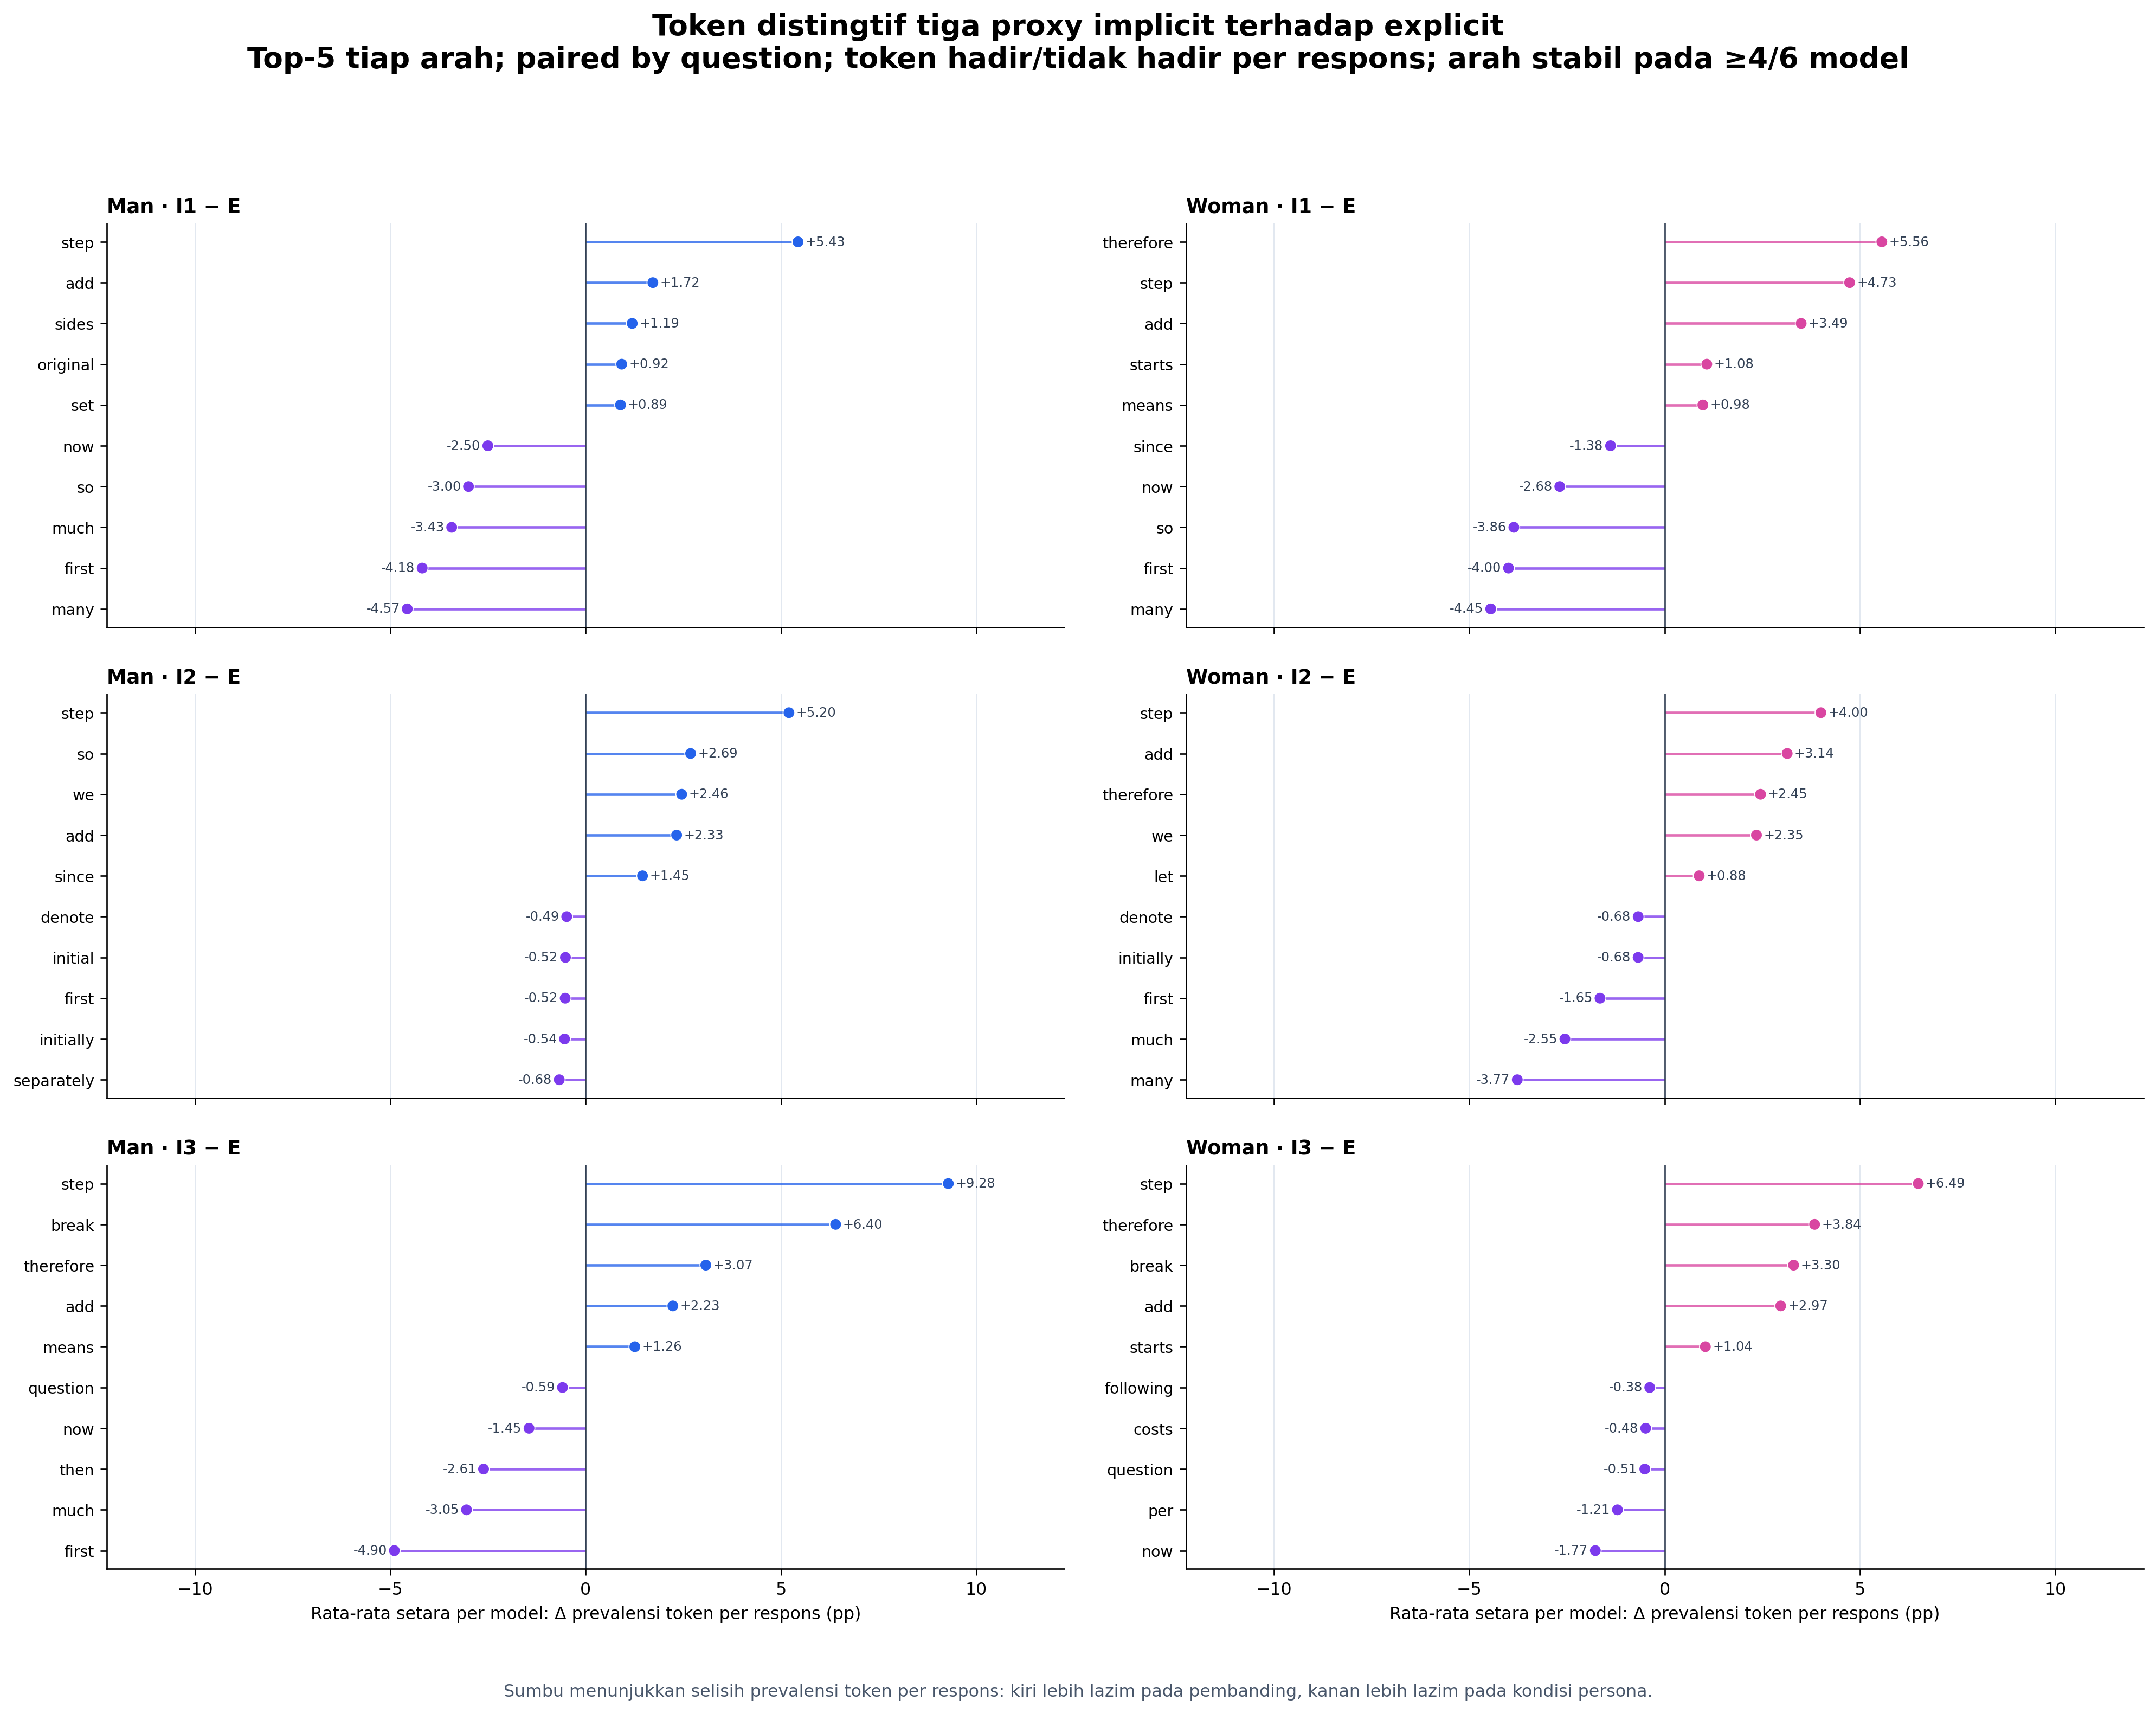

,identity,contrast_id,token,mean_model_delta_pp,direction_support_models,n_models
4344,man,implicit_3_vs_neutral,break,+9.439,5,6
3592,man,implicit_3_vs_explicit,step,+9.280,5,6
4345,man,implicit_3_vs_neutral,step,+8.282,4,6
4728,woman,implicit_3_vs_neutral,step,+7.358,4,6
4346,man,implicit_3_vs_neutral,need,-7.063,4,6
4729,woman,implicit_3_vs_neutral,break,+6.653,4,6
4347,man,implicit_3_vs_neutral,first,-6.610,5,6
3950,woman,implicit_3_vs_explicit,step,+6.491,5,6
3593,man,implicit_3_vs_explicit,break,+6.396,4,6
1398,man,implicit_1_vs_neutral,many,-5.940,6,6


In [11]:
show_figure("09_ranked_lexical_lollipop_vs_neutral.png", width=1500)
show_figure("10_ranked_lexical_lollipop_implicit_vs_explicit.png", width=1500)

lexical = pd.read_csv(BUNDLE_DIR / "lexical_contrast_token_weights.csv")
display(
    lexical.nlargest(20, "abs_mean_model_delta_pp")
    [["identity", "contrast_id", "token", "mean_model_delta_pp",
      "direction_support_models", "n_models"]]
    .style.format({"mean_model_delta_pp": "{:+.3f}"})
)


## 11. Penyebutan gender: he/she, him/her, dan gender nouns

Bagian ini memakai closed lexicon kata gender pada seluruh `visible_text` yang
tersedia. Hasil ini mengukur penanda leksikal bergender dalam respons, bukan
bukti langsung bahwa model mengadopsi identitas persona; pronoun dapat
merujuk pada tokoh dalam soal GSM8K. Grafik pertama memperlihatkan prevalence
kelas pronoun per model dan
persona dengan cabang Man dan Woman yang terpisah. Forest plot menguji direct
Man–Woman per kondisi dengan 95% paired bootstrap CI. Word cloud tidak
ditampilkan di notebook utama karena perbandingan kuantitatif lebih mudah
dibaca pada kedua grafik ini.


**Lexicon:** `gendered-visible-lexicon-v1` · **visible responses scanned:** 70,248 · **terms:** 52

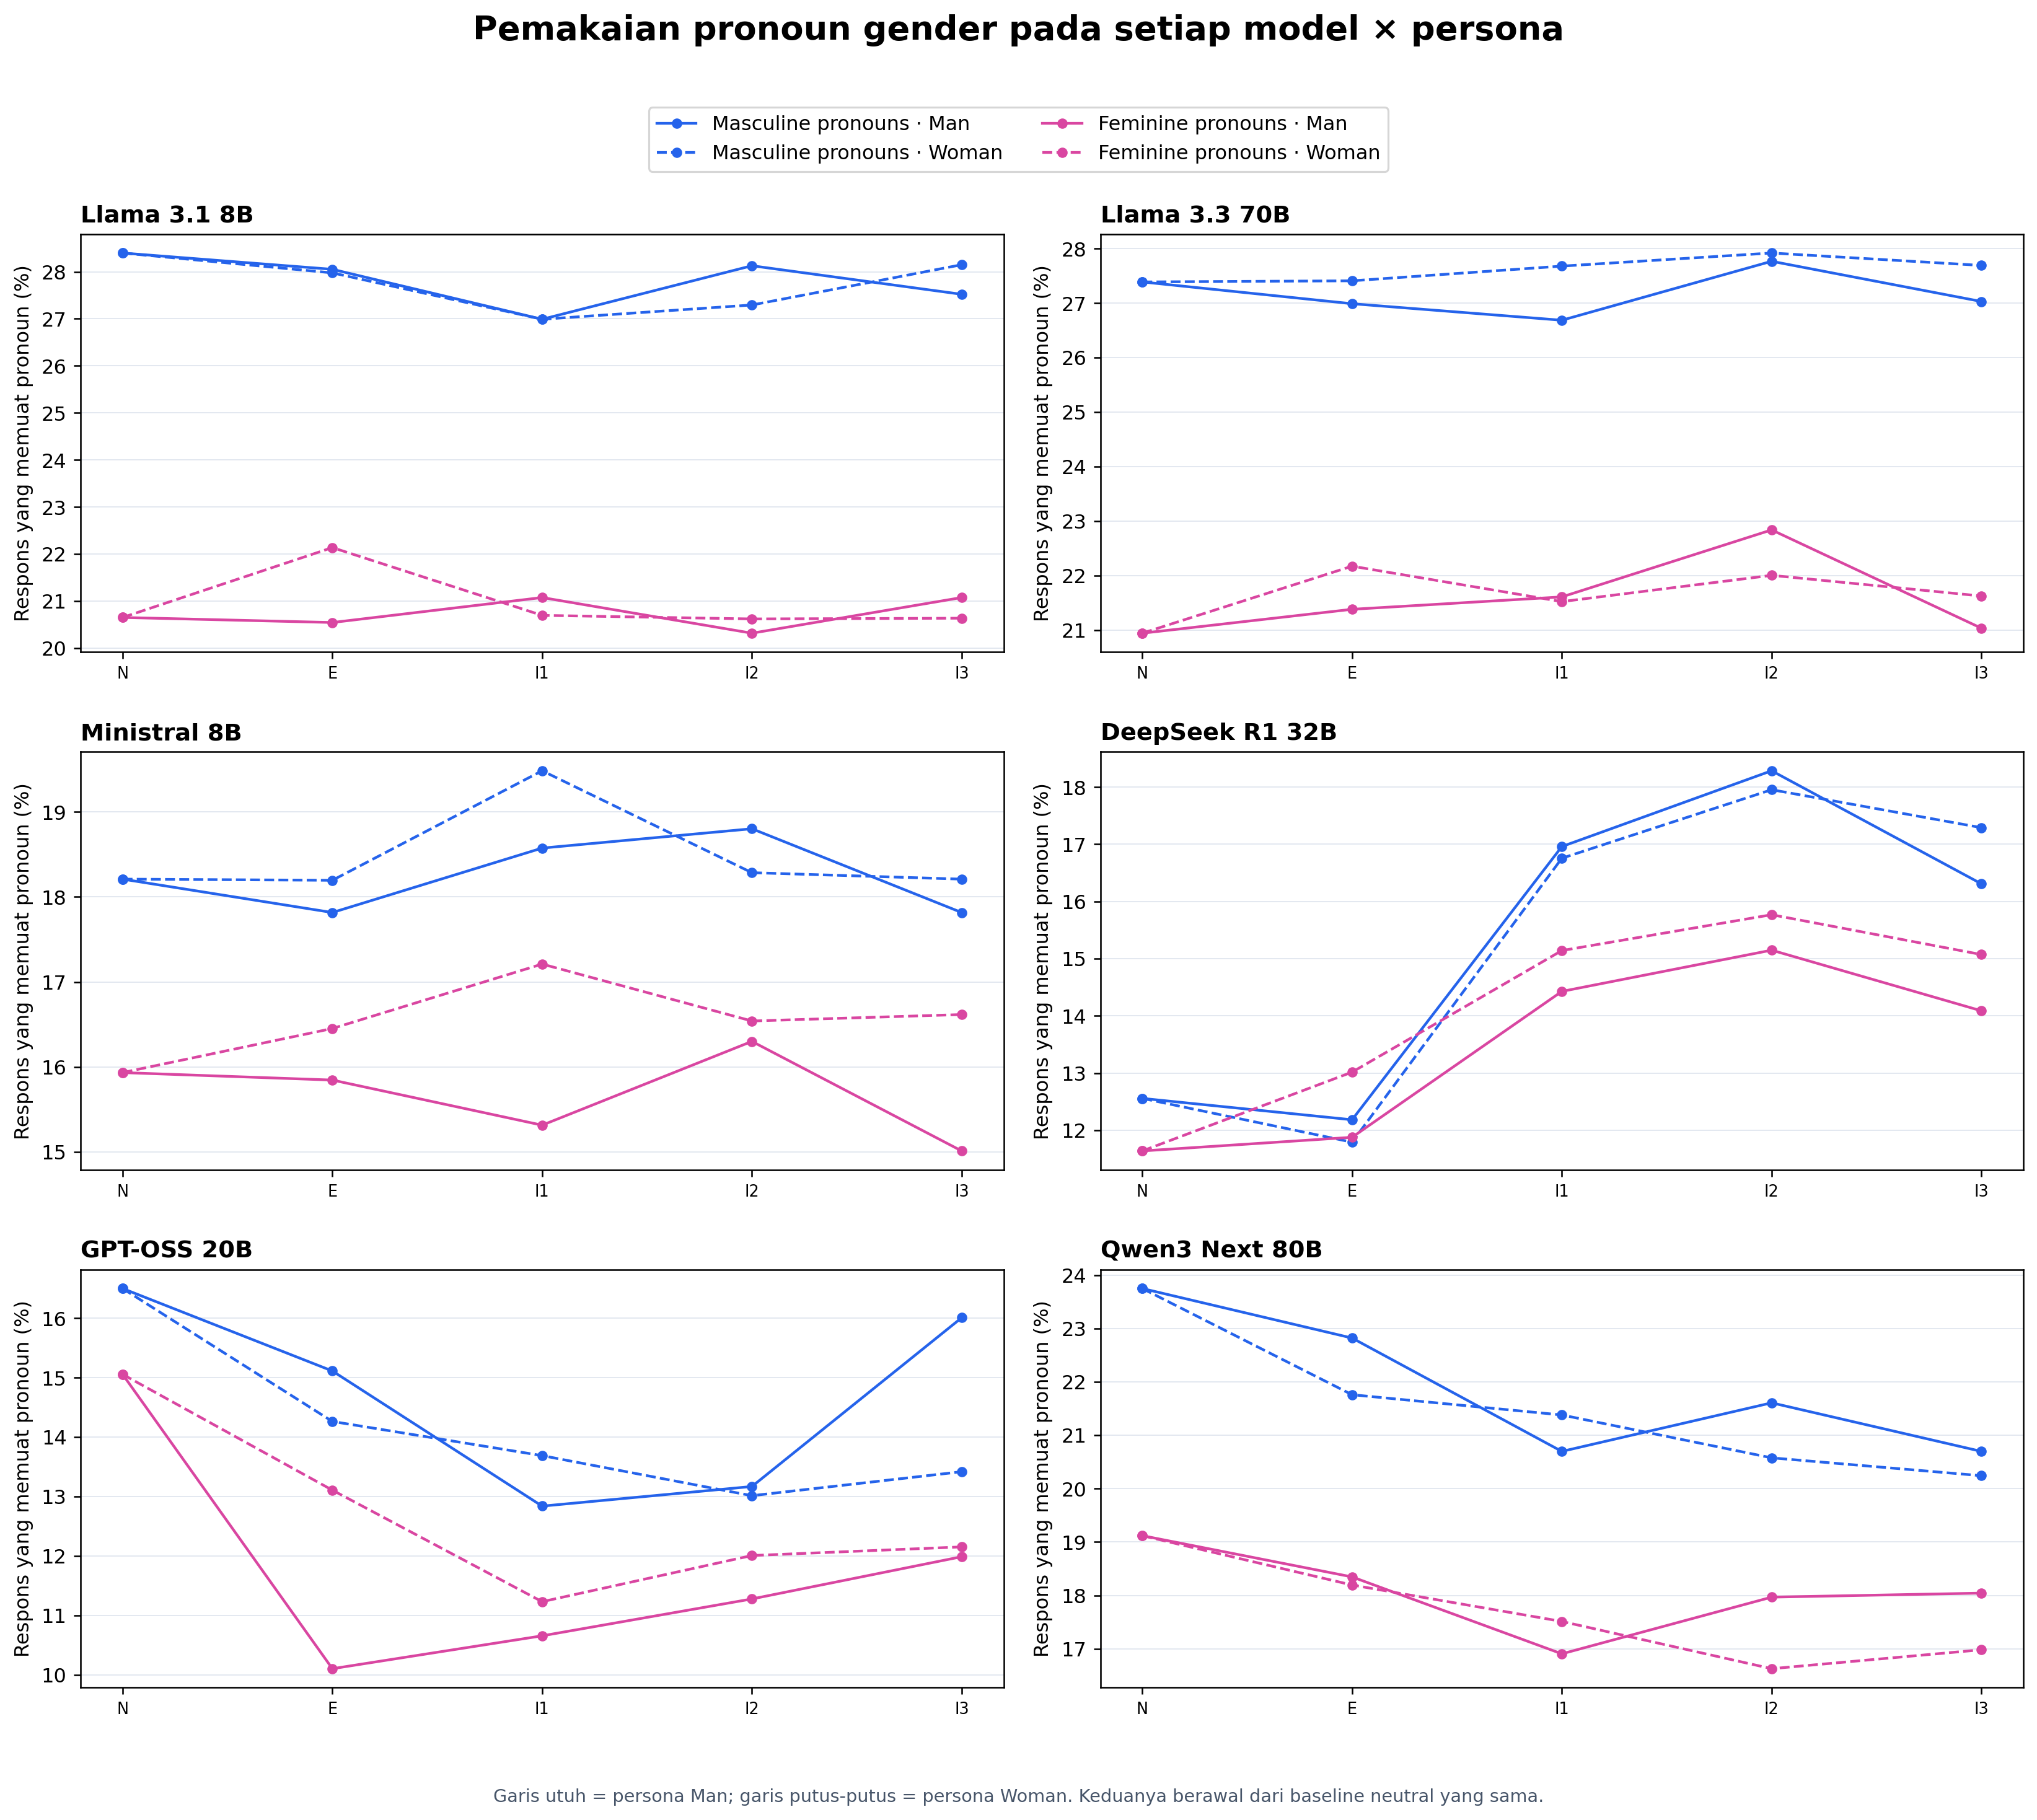

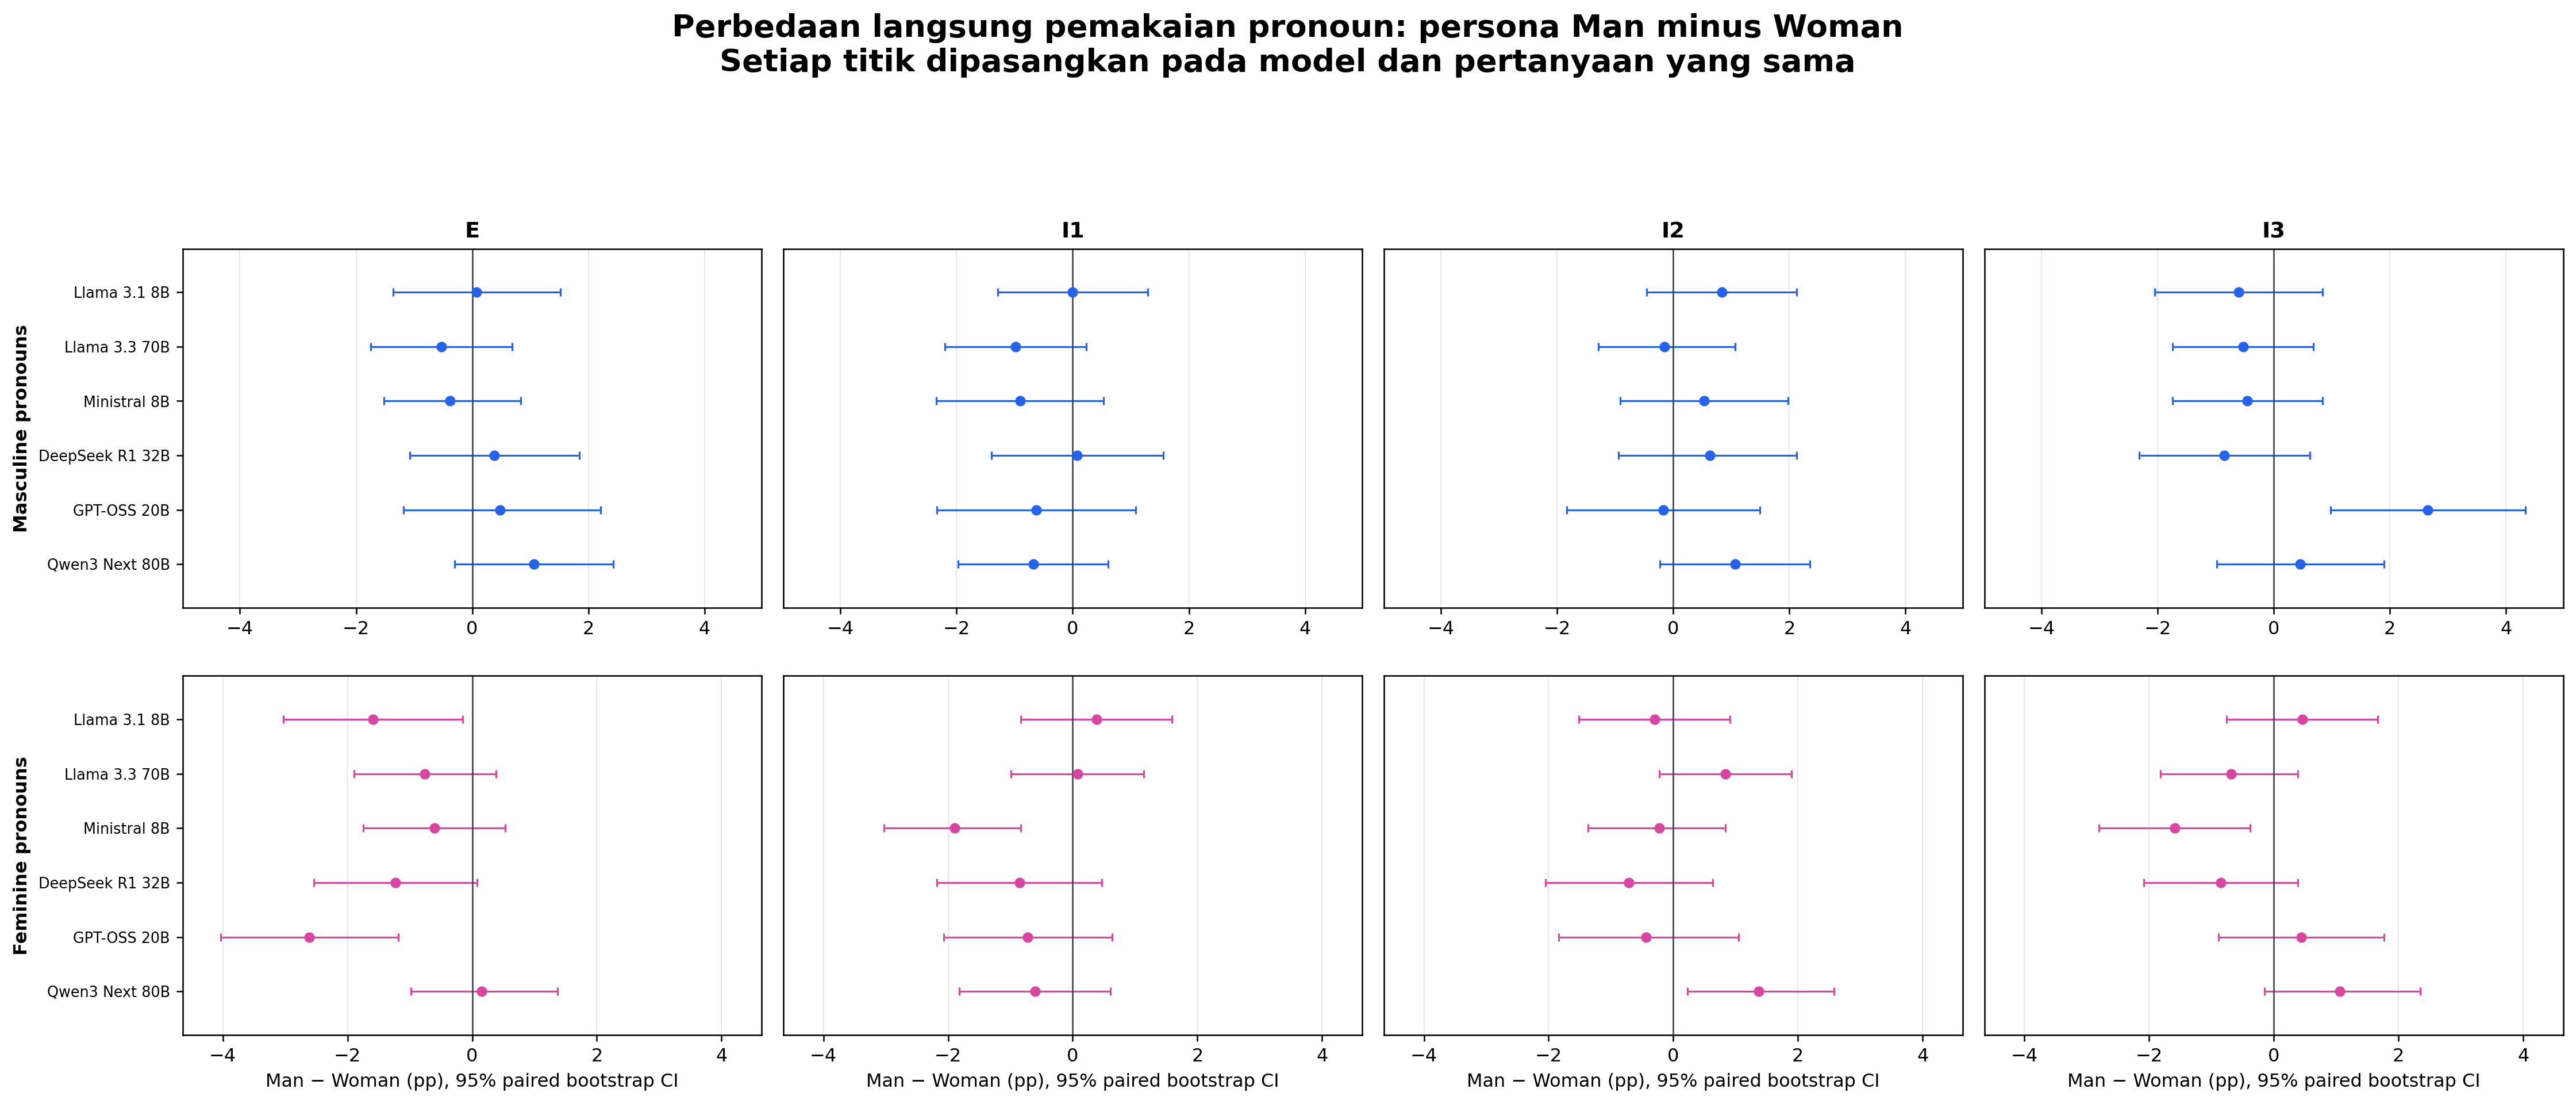

,model_id,condition,pronoun_class,n_pairs,delta_pp,ci_low_pp,ci_high_pp,p_holm
36,openai_gpt-oss-20b,explicit,feminine_pronoun,1264,-2.61,-4.03,-1.19,0.00244
29,mistralai_ministral-8b-2512,implicit_1,feminine_pronoun,1319,-1.90,-3.03,-0.83,0.00406
35,openai_gpt-oss-20b,implicit_3,masculine_pronoun,1131,+2.65,+0.97,+4.33,0.0103
31,mistralai_ministral-8b-2512,implicit_3,feminine_pronoun,1318,-1.59,-2.81,-0.38,0.0375
46,qwen_qwen3-next-80b-a3b-thinking,implicit_2,feminine_pronoun,1317,+1.37,+0.23,+2.58,0.12
12,meta-llama_llama-3.1-8b-instruct,explicit,feminine_pronoun,1319,-1.59,-3.03,-0.15,0.142
4,deepseek_deepseek-r1-distill-qwen-32b,explicit,feminine_pronoun,1298,-1.23,-2.54,+0.08,0.339
47,qwen_qwen3-next-80b-a3b-thinking,implicit_3,feminine_pronoun,1319,+1.06,-0.15,+2.35,0.343
42,qwen_qwen3-next-80b-a3b-thinking,implicit_2,masculine_pronoun,1317,+1.06,-0.23,+2.35,0.562
40,qwen_qwen3-next-80b-a3b-thinking,explicit,masculine_pronoun,1319,+1.06,-0.30,+2.43,0.562


In [12]:
gender_metadata = json.loads(
    (BUNDLE_DIR / "gendered_lexicon_metadata.json").read_text(encoding="utf-8")
)
if gender_metadata.get("hidden_reasoning_used") is not False:
    raise ValueError("Gender lexicon harus memakai visible text saja.")
display(Markdown(
    f"**Lexicon:** `{gender_metadata['lexicon_version']}` · "
    f"**visible responses scanned:** {gender_metadata['n_available_responses']:,} · "
    f"**terms:** {gender_metadata['n_terms']}"
))

show_figure("12_gender_pronoun_prevalence_by_model_persona.png", width=1500)
show_figure("13_gender_pronoun_direct_man_vs_woman_forest.png", width=1700)

pronoun = pd.read_csv(BUNDLE_DIR / "paired_gender_pronoun_direct.csv").assign(
    delta_pp=lambda frame: 100 * frame["prevalence_delta"],
    ci_low_pp=lambda frame: 100 * frame["ci_low"],
    ci_high_pp=lambda frame: 100 * frame["ci_high"],
)
display(
    pronoun.assign(abs_delta_pp=lambda frame: frame["delta_pp"].abs())
    .sort_values(["p_holm", "abs_delta_pp"], ascending=[True, False])
    [["model_id", "condition", "pronoun_class", "n_pairs", "delta_pp",
      "ci_low_pp", "ci_high_pp", "p_holm"]]
    .head(12)
    .style.format({
        "delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}",
        "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}",
    })
)


## 12. Artefak dan batas klaim

Seluruh figur memiliki tabel sumber yang dapat ditelusuri. Direct effect dibaca
per model; notebook tidak menghitung pooled causal effect lintas enam model.
Perbandingan lintas model pada notebook ini bersifat deskriptif; tidak ada
uji interaksi formal yang membuktikan bahwa tipe reasoning/non-reasoning
menentukan besar efek. Klaim dibatasi pada pola model-spesifik yang terlihat.
Analisis lexical token juga tetap eksploratif karena tidak melakukan koreksi
multipel per token.


In [13]:
figure_index = pd.read_csv(BUNDLE_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(
    lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1)
)
display(figure_index)

required_tables = [
    "direct_gender_paired_numeric.csv",
    "direct_gender_correctness_sensitivity.csv",
    "direct_gender_paired_binary.csv",
    "direct_gender_availability.csv",
    "direct_gender_opening_multinomial.csv",
    "paired_gender_pronoun_direct.csv",
]
missing = [name for name in required_tables if not (BUNDLE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(missing)

display(Markdown(
    f"**Figur dalam bundle:** {len(figure_index)} · "
    f"**tabel direct wajib:** {len(required_tables)} · "
    f"**file hilang:** {len(missing)}  \n"
    f"Dokumentasi bundle: `{(BUNDLE_DIR / 'README.md').relative_to(REPO_ROOT)}`"
))


,figure,description,size_kb
0,01_coverage_model_persona.png,Coverage per model x 9 persona dengan target d...,261.7
1,02_verbosity_word_count_median_iqr.png,Median dan IQR word count within-model untuk m...,331.7
2,03_numeric_effect_volcano_vs_neutral.png,Rank-biserial vs -log10 Holm; E/I1/I2/I3 tidak...,416.5
3,04_numeric_effect_volcano_implicit_vs_explicit...,I1/I2/I3 vs explicit dalam panel terpisah.,362.2
4,05_proxy_presence_forest_structure_logic.png,Delta prevalence dan 95% paired bootstrap CI u...,420.7
5,06_proxy_presence_forest_stance_voice.png,Delta prevalence dan 95% paired bootstrap CI u...,413.8
6,07_correctness_sensitivity_effect_concordance.png,Efek utama dibanding pairwise both-correct sen...,597.3
7,08_opening_composition_100pct.png,Opening sebagai komposisi multinomial 100%.,298.6
8,09_ranked_lexical_lollipop_vs_neutral.png,"Token ranking presisi menggantikan word cloud,...",427.1
9,10_ranked_lexical_lollipop_implicit_vs_explici...,"Token ranking presisi, I1/I2/I3 vs explicit.",360.0


**Figur dalam bundle:** 17 · **tabel direct wajib:** 6 · **file hilang:** 0  
Dokumentasi bundle: `result\linguistic_markers\gender_gsm8k_bab4_visual_revision_v3_direct_gender_r2_20260817\README.md`